# Evaluación fuera de muestra de `SM-CFHR` (`AdaptiveStructuredHuberRegressor`)

Este cuaderno consolida los resultados definitivos fuera de muestra (*out-of-fold*, OOF) almacenados en `resultados/evaluacion_ashr_oof/` sin reentrenar modelos (`Fixed`: `14,625/14,625` unidades; `HPO`: `14,625/14,625` unidades).

## Índice
1. [Capítulo 1. Alcance experimental, formulación e integridad de artefactos OOF](#Capítulo-1.-Alcance-experimental,-formulación-e-integridad-de-artefactos-OOF)
2. [Capítulo 2. Auditoría de optimización bayesiana y validación causal anidada](#Capítulo-2.-Auditoría-de-optimización-bayesiana-y-validación-causal-anidada)
3. [Capítulo 3. Comparación frente a modelos de biblioteca](#Capítulo-3.-Comparación-frente-a-modelos-de-biblioteca)
4. [Capítulo 4. Evaluación general sobre 23 modelos, inferencia estadística y criterios R3](#Capítulo-4.-Evaluación-general-sobre-23-modelos,-inferencia-estadística-y-criterios-R3)
5. [Capítulo 5. Análisis intra-dataset por planta, capacidad, bloque temporal y estrategia](#Capítulo-5.-Análisis-intra-dataset-por-planta,-capacidad,-bloque-temporal-y-estrategia)
6. [Capítulo 6. Transferencia entre plantas y grupos geográficos](#Capítulo-6.-Transferencia-entre-plantas-y-grupos-geográficos)
7. [Capítulo 7. Configuración fija frente a HPO, diagnósticos en D+1 y coste computacional](#Capítulo-7.-Configuración-fija-frente-a-HPO,-diagnósticos-en-D+1-y-coste-computacional)
8. [Capítulo 8. Síntesis de hallazgos y limitaciones](#Capítulo-8.-Síntesis-de-hallazgos-y-limitaciones)

# Capítulo 1. Alcance experimental, formulación e integridad de artefactos OOF

## 1.1 Alcance e identificadores de versión
La evaluación cubre `17` plantas fotovoltaicas en Colombia (`9.8` a `388.0 MW`, distribuidas en `7` grupos geográficos) bajo `28` escenarios experimentales (`4` escenarios `D+1`, `8` recursivos sin clima, `8` directos sin clima y `8` recursivos con pronóstico `NOAA GEFSv12`). Los `28` escenarios comparten plantas y ventanas temporales, por lo que no deben interpretarse como `28` conjuntos de datos independientes.

- **Paquete y licencia:** `sm-cfhr`, `PolyForm-Noncommercial-1.0.0` (etiqueta `v3.0.0`).
- **Protocolo y semilla:** `v1.0.3-exact-recursive-state`, semilla `2026`.
- **Alcance del dominio:** evaluación circunscrita al dominio solar colombiano sin datasets externos no solares.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, Markdown, display
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

_CUR = Path.cwd().resolve()
ROOT = next(p for p in (_CUR, *_CUR.parents) if (p / "experiments" / "config_ashr_congelada.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import sm_cfhr
from sm_cfhr import (
    SCENARIOS_28,
    SMCFHRRegressor,
    analyze_effective_design,
    evaluate_r3_superiority,
    export_full_scientific_artifacts,
    summarize_hpo_trials,
    verify_benchmark_inventory,
)
from sm_cfhr.plotting import plot_nested_cv_scheme, plot_optuna_convergence
from sm_cfhr.visualizacion_pedagogica import generate_pedagogical_figures
from src.ashr_oof_pipeline import (
    build_descriptive_summary,
    export_paper_tables,
    load_frozen_config,
    load_oof_bundle,
    validate_oof_artifacts,
)
from src.ashr_oof_pipeline.oof_runner import run_oof_definitivo

CFG = load_frozen_config(ROOT)
OOF_DIR = ROOT / CFG.get("rutas_contrato", {}).get("oof_dir", "resultados/evaluacion_ashr_oof")
HPO_TRIALS_DIR = ROOT / CFG.get("rutas_contrato", {}).get("hpo_trials_dir", "resultados/evaluacion_ashr_oof/hpo_trials")
FIG_DIR = OOF_DIR / "figuras"
TAB_DIR = OOF_DIR / "tablas_paper"
SCOPE_AUTHORIZED = bool(CFG.get("autorizacion_alcance_solar_docente", False))

print("sm_cfhr:", sm_cfhr.__version__, "| SHA-256 núcleo:", CFG["sha256_src_adaptive_structured_huber"])

C:\Users\Enma\miniconda3\envs\solarpv-eda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sm_cfhr: 1.0.3 | SHA-256 núcleo: 27a9fda4fa8b7ef0d95faf9e925e47ade9ed8f25e9ea5d97d6d7cf1c00ddde83


## 1.2 Formulación matemática, API `scikit-learn` y alineación de predicciones

Para evitar que las centrales de mayor capacidad (`388.0 MW` frente a `9.8 MW`, una razón de $39{,}6\times$) dominen el ajuste, la energía diaria o acumulada directa se normaliza por la cota física vigente al origen $B_i = \mathrm{cap}_i \cdot 24\,000\;\text{kWh/día}$ ($c_i \in [0,1]$). Posteriormente se estandariza mediante la mediana $m_c$ y la desviación robusta $\hat{\sigma}_c = \max(1{,}4826\,\mathrm{MAD}(c), 10^{-6})$:

$$\min_{\theta_0 \in \mathbb{R},\; \theta \in \mathcal{C}} \; \frac{1}{n}\sum_{i=1}^n \rho_\delta\!\left(\tilde{c}_i - \theta_0 - z_i^\top \theta\right) + \frac{1}{2}\sum_{j \in \mathcal{G}_{\mathrm{lin}}} \alpha_{\mathrm{lin}}\,\theta_j^2 + \frac{1}{2}\sum_{j \in \mathcal{G}_{\mathrm{meteo}}} \alpha_{\mathrm{meteo}}\,\theta_j^2, \quad \mathcal{C} = \{\theta : \theta_j \ge 0 \;\forall j \in \mathcal{M}_{\mathrm{pos}}\}.$$

A continuación se verifica la compatibilidad del estimador con `Pipeline` y `clone`, el estado criptográfico del manifiesto OOF y la intersección exacta de claves entre `Fixed`, `HPO` y los 22 benchmarks.

In [2]:
hp_cfg = CFG["parametros_modelo"]["fixed_config"]
demo_est = SMCFHRRegressor(
    delta=CFG["parametros_modelo"]["delta"],
    alpha_lin=hp_cfg["alpha_lin"],
    alpha_meteo=hp_cfg["alpha_meteo"],
    structured=hp_cfg["structured"],
    use_mono=hp_cfg["use_mono"],
    random_state=CFG["parametros_modelo"]["random_state"],
)
_ = Pipeline([("scaler", StandardScaler()), ("sm_cfhr", clone(demo_est))])
assert isinstance(demo_est, BaseEstimator) and isinstance(demo_est, RegressorMixin)

_ = run_oof_definitivo(execute=False, root=ROOT)
val_status = validate_oof_artifacts(OOF_DIR, CFG["sha256_src_adaptive_structured_huber"])
inv_df = verify_benchmark_inventory(ROOT)

bundle = None
ped_figs = {}
if val_status["state"] == "VALID":
    bundle = load_oof_bundle(OOF_DIR, root=ROOT)
    spa_p = OOF_DIR / "inferencia" / "tabla_spa.csv"
    if spa_p.exists():
        bundle["tabla_spa"] = pd.read_csv(spa_p)
    ped_figs = generate_pedagogical_figures(OOF_DIR, ROOT)
    align_df = pd.read_csv(OOF_DIR / "inferencia" / "auditoria_alineacion_benchmarks.csv")
    ex_df = align_df[align_df["n_extra_excluded"] > 0][
        ["scenario_id", "n_ashr_raw", "n_bench_keys", "n_extra_excluded", "n_aligned_common", "fixed_hpo_keys_identical"]
    ]
    display(ex_df)
    display(Markdown(
        f"El manifiesto OOF registra estado `{val_status['state']}` y el inventario cubre `{len(inv_df)}/28` escenarios. "
        f"Las claves de `SM-CFHR-Fixed` y `SM-CFHR-HPO` coinciden en `{int(align_df['fixed_hpo_keys_identical'].sum())}/28` escenarios. "
        f"En `{len(ex_df)}/28` escenarios (todos de la suite `DirectoSinClima`) se excluyeron entre `2` y `63` orígenes tempranos al intersectar con las claves oficiales del benchmark, mientras `D+1` y los escenarios recursivos mantuvieron alineación completa (`0` exclusiones). "
        f"Todas las comparaciones siguientes operan sobre ese soporte común pareado."
    ))

,scenario_id,n_ashr_raw,n_bench_keys,n_extra_excluded,n_aligned_common,fixed_hpo_keys_identical
12,DirectoSinClima_espaciotemporal_7d,1679,1718,4,1675,True
13,DirectoSinClima_intraplanta_7d,1624,1600,63,1561,True
14,DirectoSinClima_espaciotemporal_14d,812,852,2,810,True
15,DirectoSinClima_intraplanta_14d,783,784,33,750,True
16,DirectoSinClima_espaciotemporal_21d,513,553,2,511,True
17,DirectoSinClima_intraplanta_21d,488,499,22,466,True
18,DirectoSinClima_espaciotemporal_28d,372,411,2,370,True
19,DirectoSinClima_intraplanta_28d,350,365,17,333,True


El manifiesto OOF registra estado `VALID` y el inventario cubre `28/28` escenarios. Las claves de `SM-CFHR-Fixed` y `SM-CFHR-HPO` coinciden en `28/28` escenarios. En `8/28` escenarios (todos de la suite `DirectoSinClima`) se excluyeron entre `2` y `63` orígenes tempranos al intersectar con las claves oficiales del benchmark, mientras `D+1` y los escenarios recursivos mantuvieron alineación completa (`0` exclusiones). Todas las comparaciones siguientes operan sobre ese soporte común pareado.

# Capítulo 2. Auditoría de optimización bayesiana y validación causal anidada

En `SM-CFHR-HPO`, cada unidad aplicable ejecuta `25` evaluaciones con Optuna TPE sobre `3` particiones causales internas. Se audita si los estudios respetaron el presupuesto de evaluaciones y las brechas temporales y espaciales exigidas.

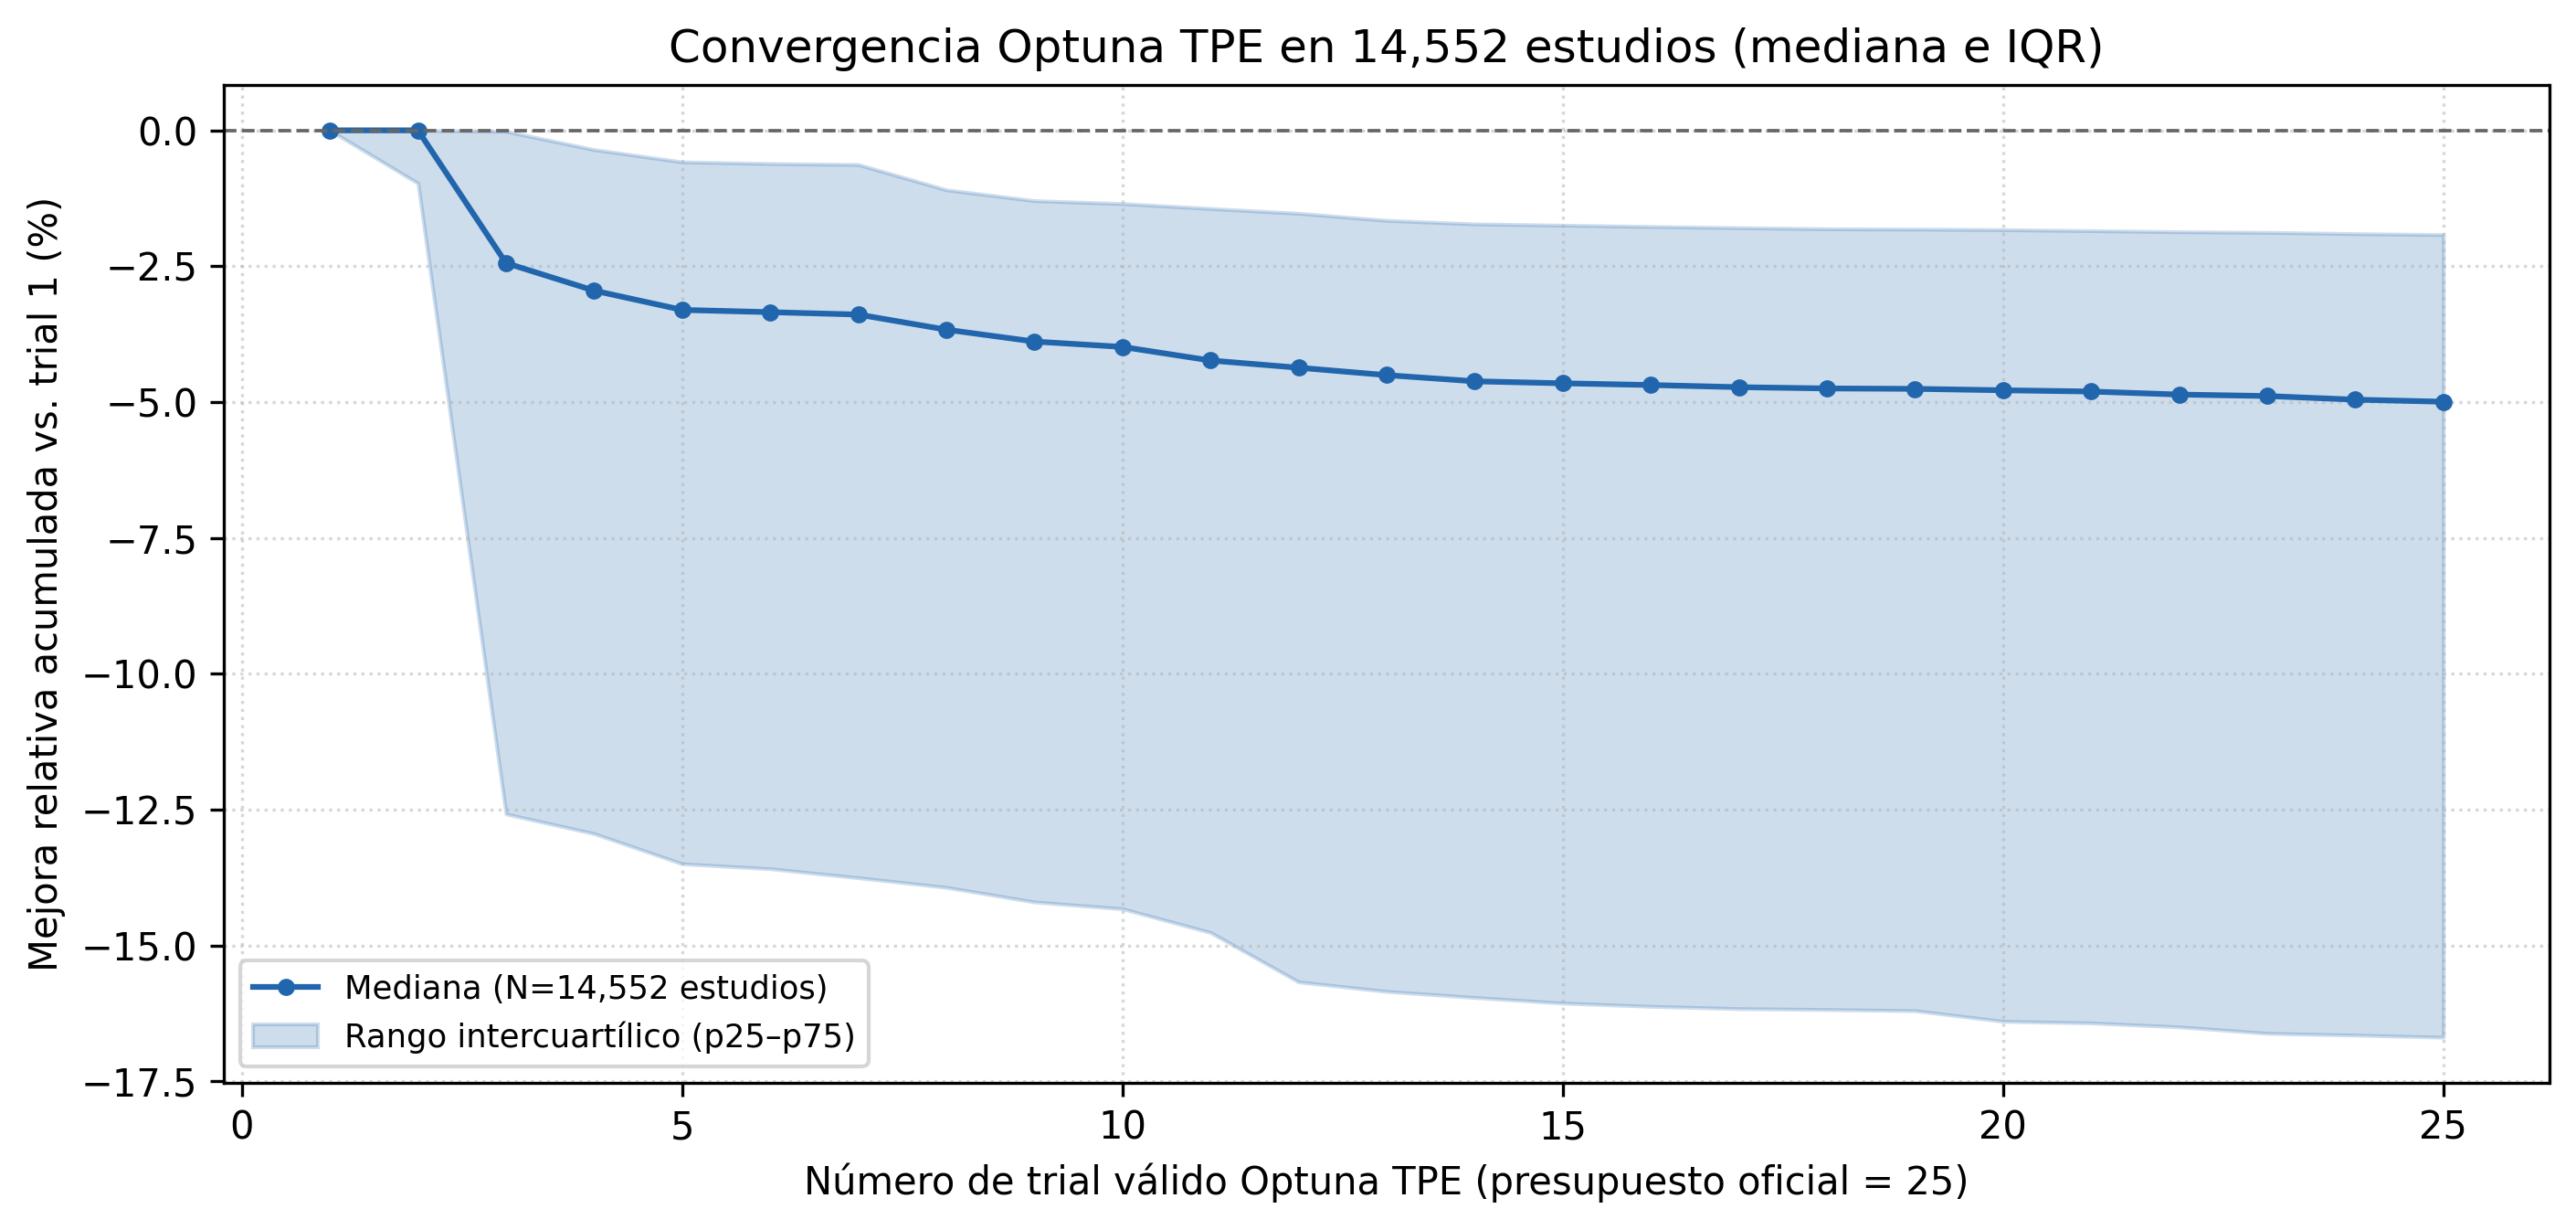

Se registraron `14,552` estudios `(scenario_id, outer_fold)` con `363,800` evaluaciones válidas (`mín=25`, `máx=25` por estudio); `8` estudios reanudados tras interrupción contienen `26` filas (`1` trial interrumpido y `25` válidos), y `73` unidades tempranas sin historial mínimo suficiente no ejecutaron búsqueda. La mejora observada durante los `25` trials corresponde al error interno en las `3` particiones de ajuste y no garantiza ganancia equivalente fuera de muestra.

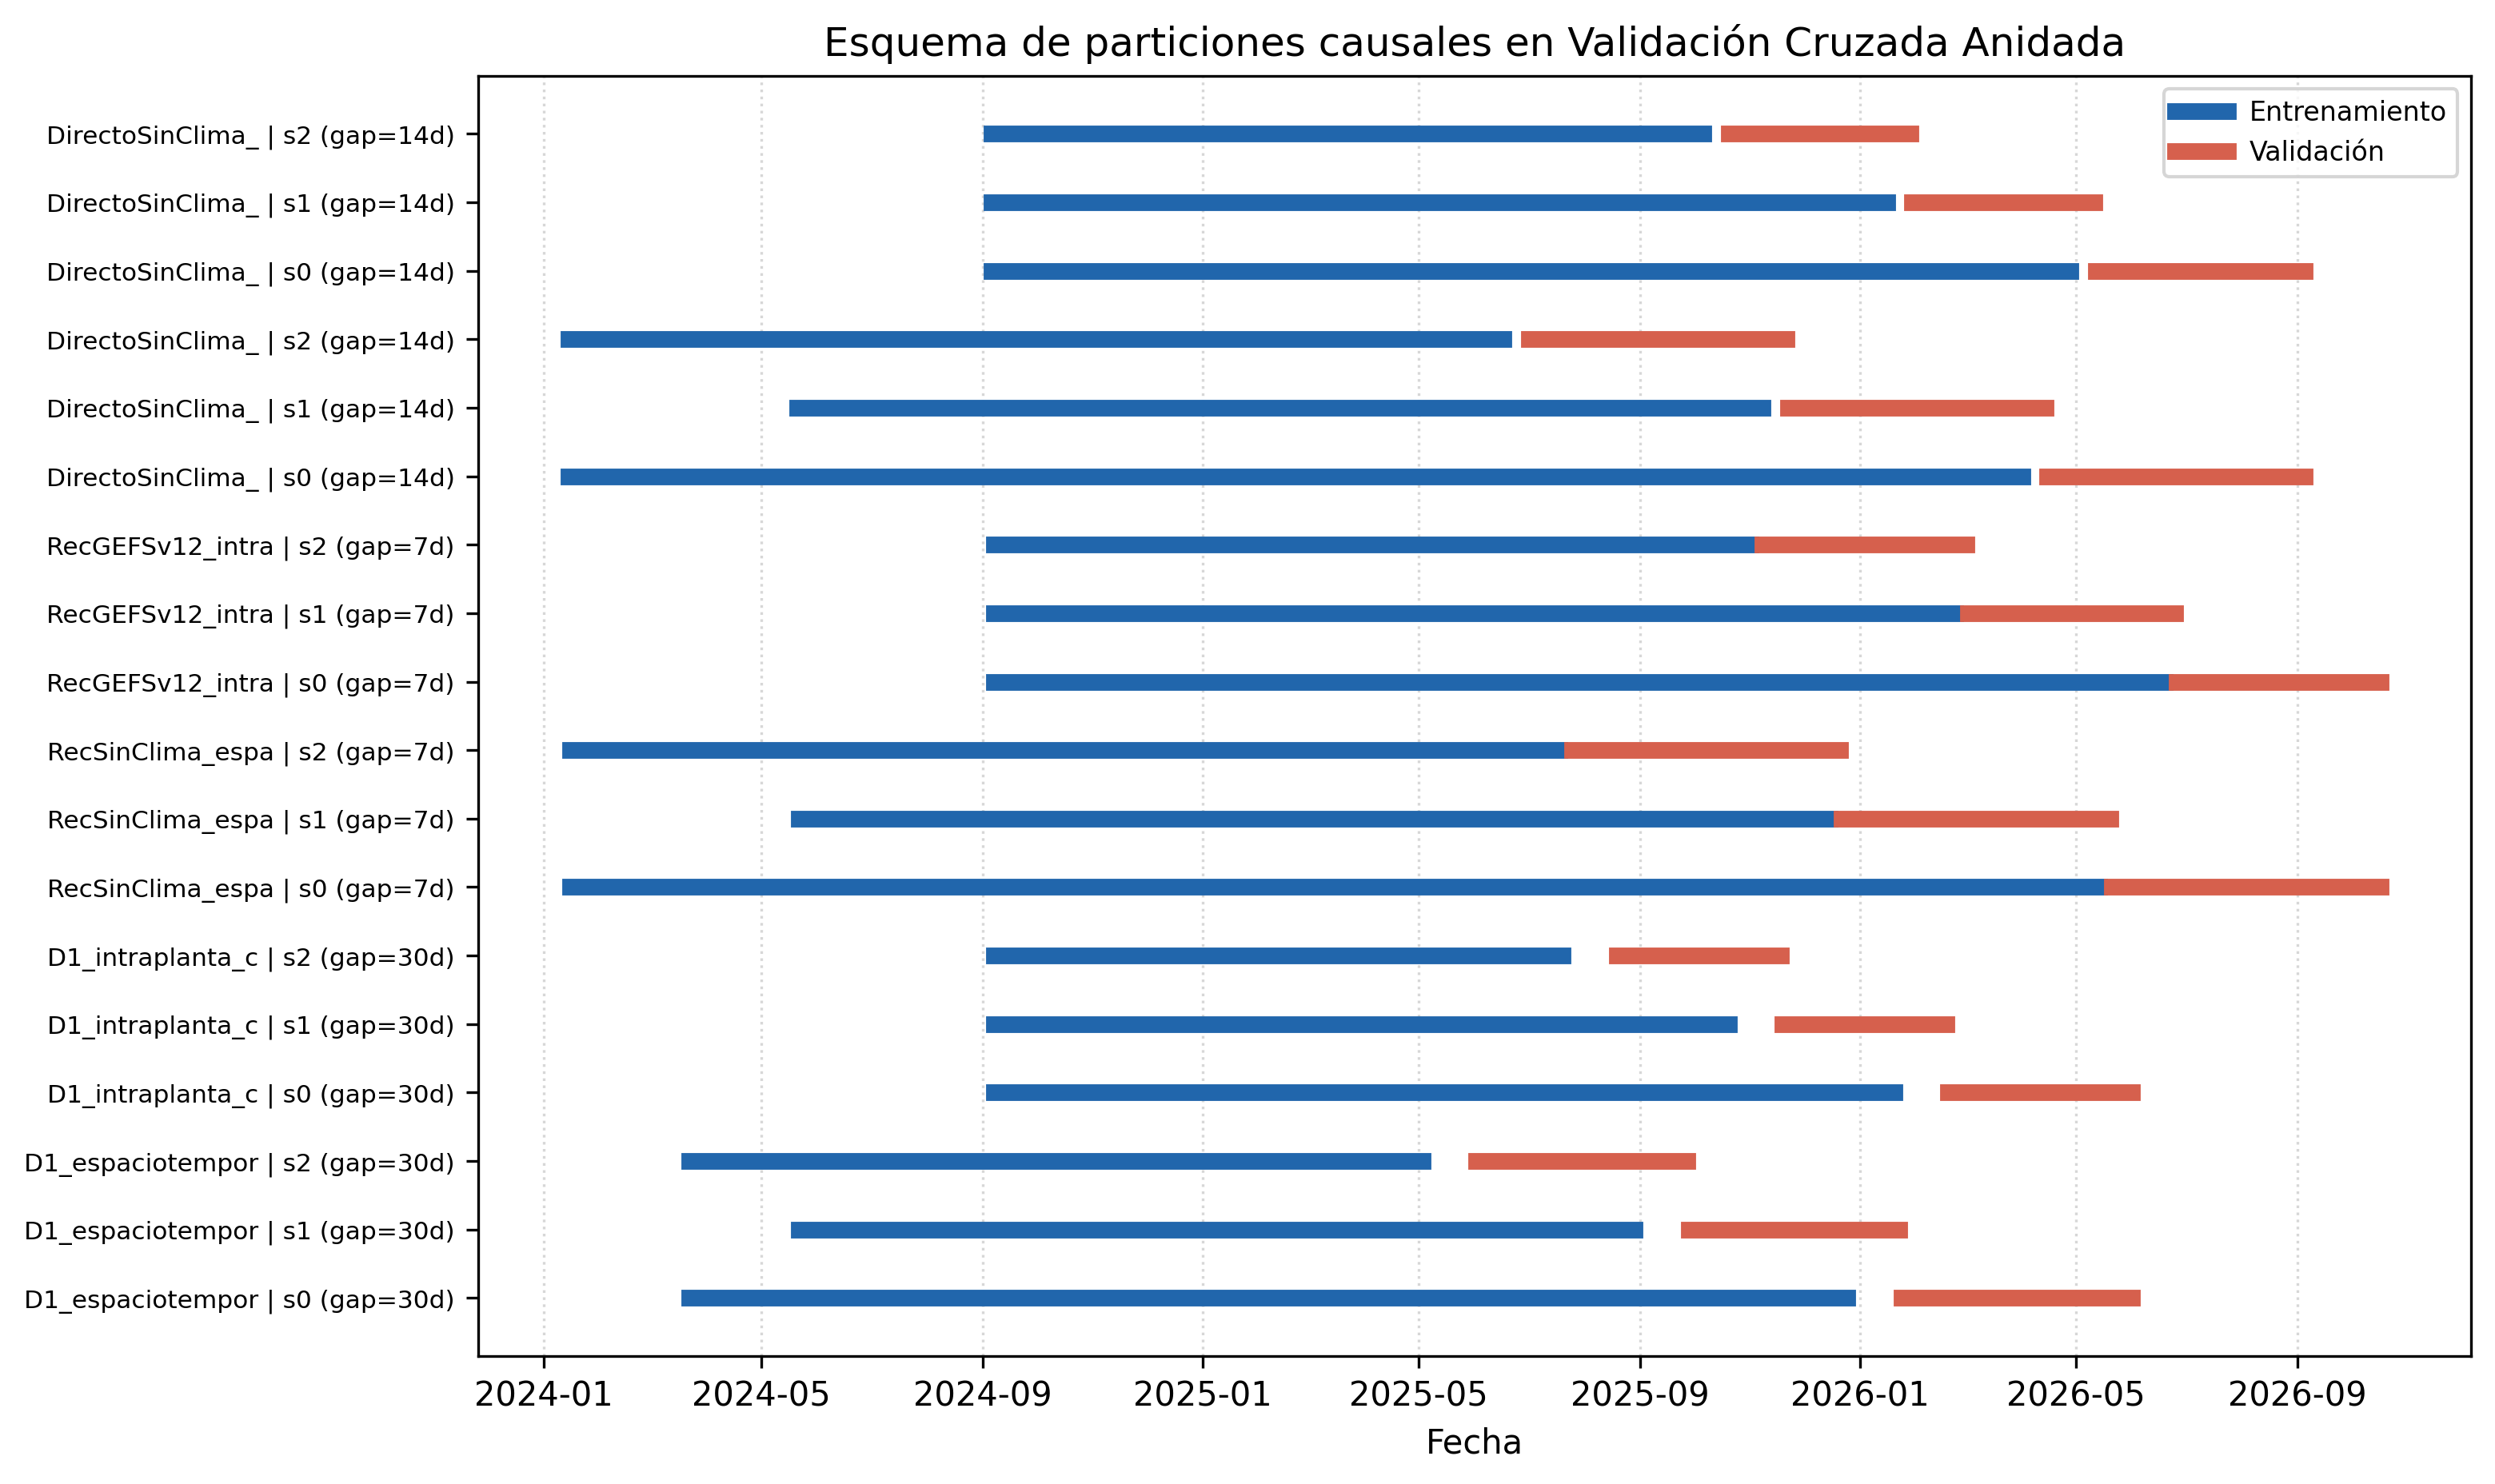

La reconstrucción de `18` particiones representativas de las cuatro suites verifica una brecha temporal mínima de `7` días (`0` solapamientos con el horizonte objetivo) y separación espacial estricta (`spatial_disjoint=True`) en los splits espaciotemporales. Esta auditoría confirma ausencia de fuga temporal o espacial en los splits representativos, aunque los índices individuales de cada estudio no se almacenaron por separado.

In [3]:
if HPO_TRIALS_DIR.exists():
    trial_files = sorted(HPO_TRIALS_DIR.glob("*.csv"))
    hpo_trials_df = pd.concat([pd.read_csv(f).assign(scenario_id=f.stem) for f in trial_files], ignore_index=True)
    hpo_summary_df = summarize_hpo_trials(hpo_trials_df)
    plot_optuna_convergence(hpo_trials_df, FIG_DIR)
    display(Image(filename=str(FIG_DIR / "fig07_optuna_convergencia.png")))
    n_studies = len(hpo_summary_df)
    n_valid_tot = int(hpo_summary_df["n_valid_trials"].sum())
    min_v, max_v = int(hpo_summary_df["n_valid_trials"].min()), int(hpo_summary_df["n_valid_trials"].max())
    n_26_rows = int((hpo_summary_df["n_rows_logged"] == 26).sum())
    display(Markdown(
        f"Se registraron `{n_studies:,}` estudios `(scenario_id, outer_fold)` con `{n_valid_tot:,}` evaluaciones válidas (`mín={min_v}`, `máx={max_v}` por estudio); "
        f"`{n_26_rows}` estudios reanudados tras interrupción contienen `26` filas (`1` trial interrumpido y `25` válidos), y `73` unidades tempranas sin historial mínimo suficiente no ejecutaron búsqueda. "
        f"La mejora observada durante los `25` trials corresponde al error interno en las `3` particiones de ajuste y no garantiza ganancia equivalente fuera de muestra."
    ))

nested_audit_path = OOF_DIR / "particiones" / "nested_cv_audit.csv"
if nested_audit_path.exists():
    nested_audit_df = pd.read_csv(nested_audit_path)
    plot_nested_cv_scheme(nested_audit_df, FIG_DIR)
    display(Image(filename=str(FIG_DIR / "fig06_nested_cv_esquema.png")))
    min_gap = int(nested_audit_df["effective_gap_days"].min())
    et_disj = bool(nested_audit_df.loc[nested_audit_df["task"] == "espaciotemporal", "spatial_disjoint"].all())
    display(Markdown(
        f"La reconstrucción de `{len(nested_audit_df)}` particiones representativas de las cuatro suites verifica una brecha temporal mínima de `{min_gap}` días (`0` solapamientos con el horizonte objetivo) "
        f"y separación espacial estricta (`spatial_disjoint={et_disj}`) en los splits espaciotemporales. "
        f"Esta auditoría confirma ausencia de fuga temporal o espacial en los splits representativos, aunque los índices individuales de cada estudio no se almacenaron por separado."
    ))

# Capítulo 3. Comparación frente a modelos de biblioteca

## 3.1 Definiciones operativas de evaluación
- **`MAE_macro` (`kWh/día`):** promedio del error absoluto por planta (`code`) y posterior promedio equiponderado entre las `17` centrales; iguala el peso respecto a la duración de las series, aunque en unidades de energía conserva la escala de potencia instalada (`9.8` a `388.0 MW`), la cual se normaliza explícitamente mediante `MAE_CF_macro`.
- **`p-valor bruto` frente a `p-valor ajustado` (Holm–Bonferroni):** el ajuste secuencial controla la tasa de error familiar (FWER $\le 0{,}05$) dentro de la familia de contrastes.
- **`MCS` (*Model Confidence Set*, $\alpha=0{,}10$):** conjunto de modelos no descartables como inferiores mediante *bootstrap* estacionario; permanecer en el MCS indica compatibilidad con el mejor grupo, no superioridad demostrada salvo cuando sobrevive un único modelo.
- **`SPA` (*Superior Predictive Ability*):** contrasta bajo $H_0$ si ningún competidor supera al modelo tomado como referencia.
- **Tamaño del efecto (`Cohen's dz`) e `IC 95%`:** cuantifican la magnitud estandarizada de la diferencia pareada ($d_z \le -0{,}20$ favorece a `SM-CFHR`) y su incertidumbre. En el protocolo congelado, los contrastes con $T_{\mathrm{eff}} < 2H$ se marcan como de potencia insuficiente.

## 3.2 Posición global frente a las nueve bibliotecas

,metodo,rango_en_10
0,SM-CFHR-Fixed,1.642857
1,BayesianRidge,3.285714
2,Lasso,3.750000
3,Ridge,3.964286
4,Random Forest,4.964286
5,XGBoost,6.285714
6,k-NN,6.535714
7,HistGradientBoosting,7.321429
8,SVR,8.142857
9,DecisionTree,9.107143


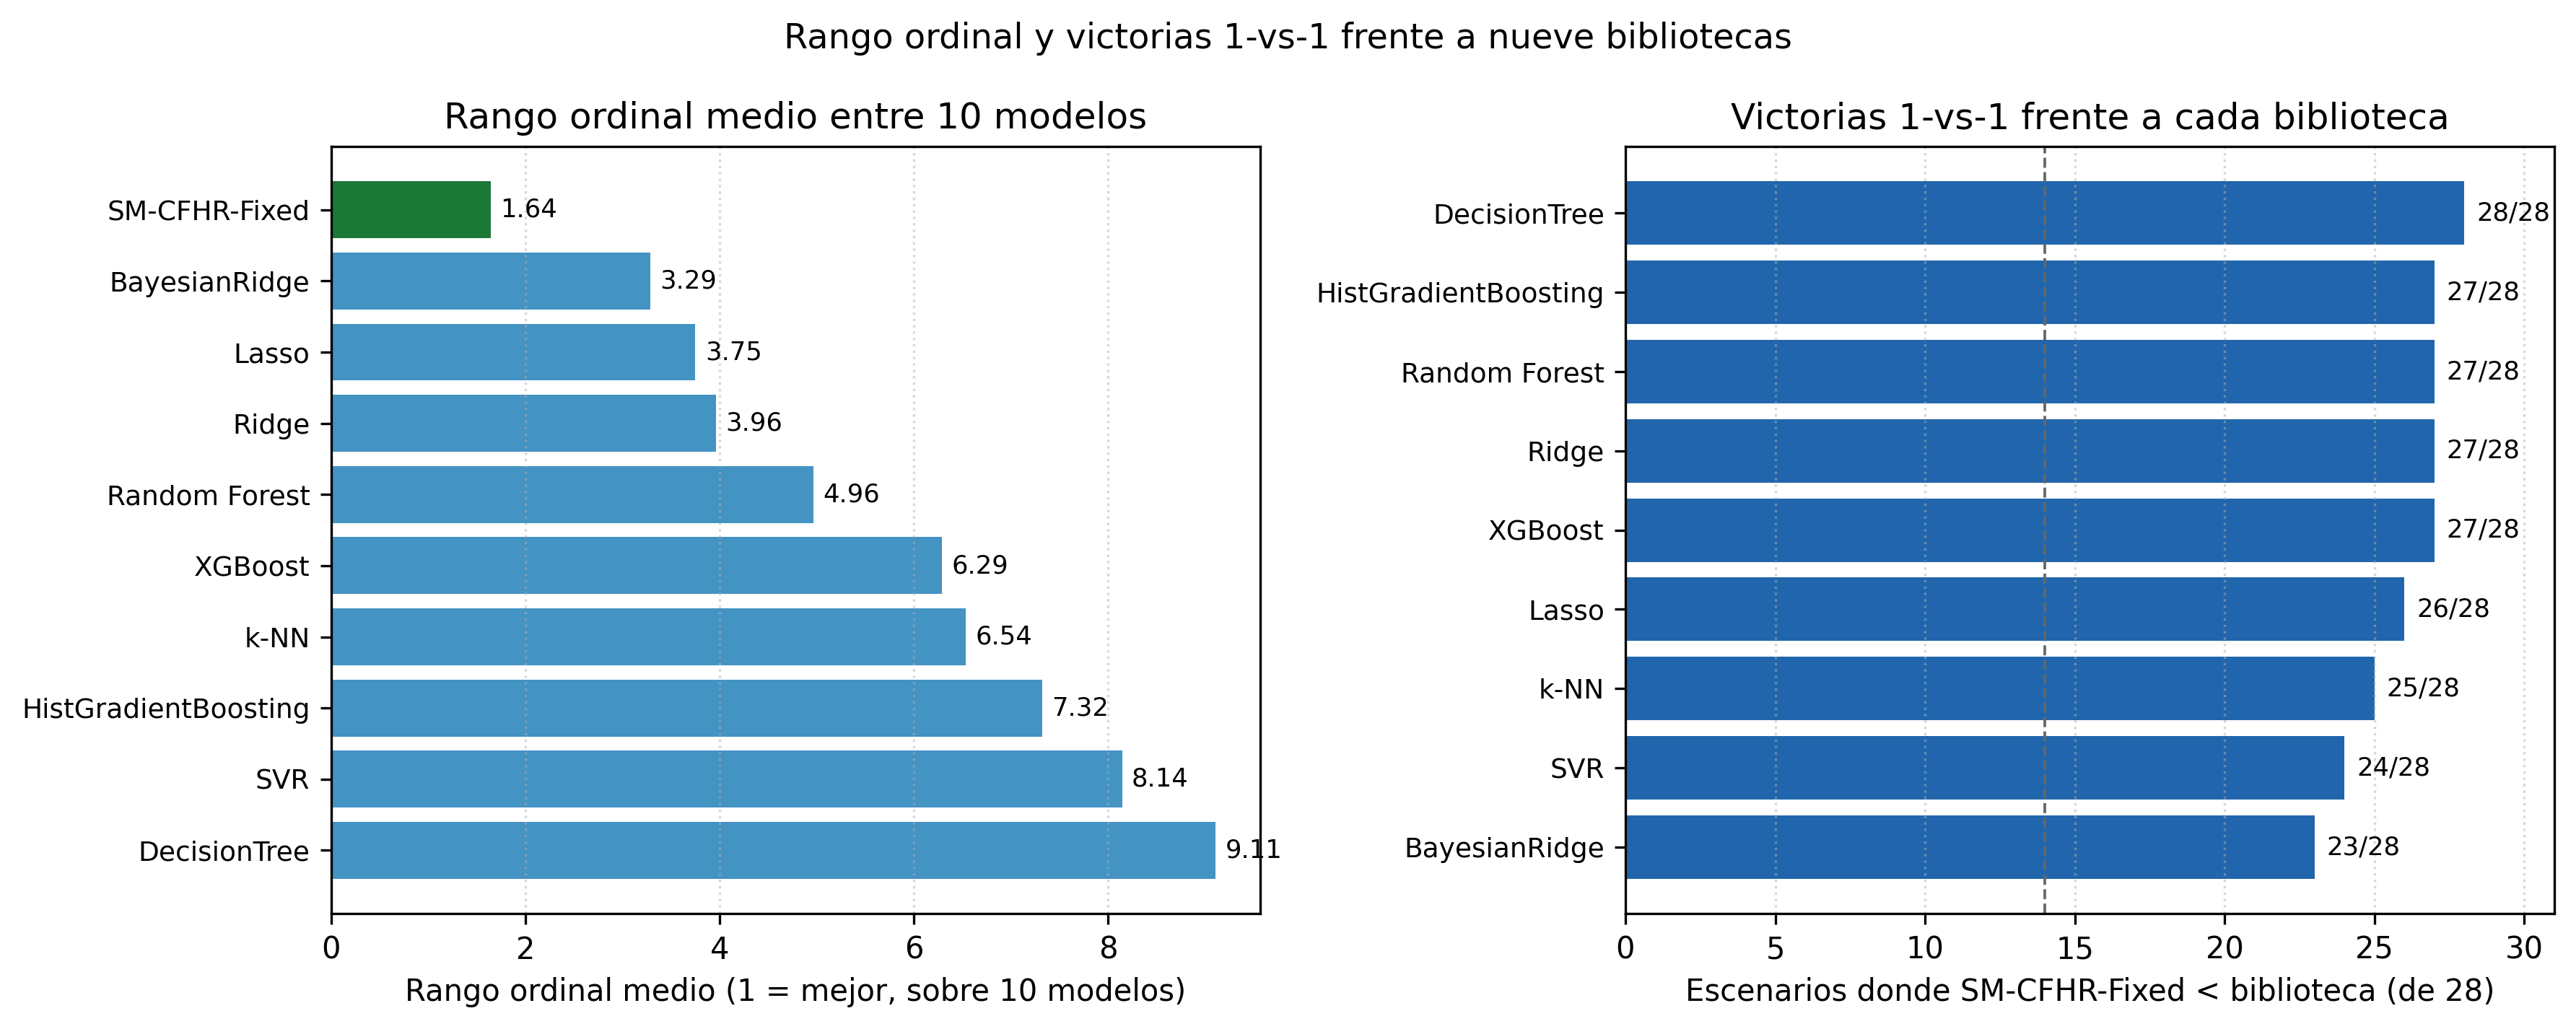

Sin ajuste de hiperparámetros ($B=0$), `SM-CFHR-Fixed` obtiene rango medio **`1.64 / 10`**, seguido por `BayesianRidge` (`3.29`), `Lasso` (`3.75`) y `Ridge` (`3.96`). En comparaciones directas `1-vs-1` supera a cada biblioteca entre `23/28` (frente a `BayesianRidge`) y `28/28` escenarios (frente a `DecisionTree`), y permanece en el MCS exclusivo de bibliotecas en `28/28` escenarios (`5/28` como único superviviente).

Estos resultados describen un buen desempeño relativo en el conjunto de bibliotecas, aunque promedian escenarios que comparten las mismas `17` plantas y no sustituyen a las pruebas pareadas ni al control por multiplicidad.

In [4]:
if bundle is not None:
    rank10 = pd.read_csv(OOF_DIR / "inferencia" / "ranking_bibliotecas_only.csv")
    mcs_lib = pd.read_csv(OOF_DIR / "inferencia" / "mcs_bibliotecas_only.csv")
    r_mean = rank10.groupby("metodo", as_index=False)["rango_en_10"].mean().sort_values("rango_en_10").reset_index(drop=True)
    display(r_mean)
    display(Image(filename=str(ped_figs["P01"][0])))
    ashr_rk = float(r_mean.loc[r_mean["metodo"] == "SM-CFHR-Fixed", "rango_en_10"].iloc[0])
    br_rk = float(r_mean.loc[r_mean["metodo"] == "BayesianRidge", "rango_en_10"].iloc[0])
    n_surv = int(mcs_lib["in_mcs_lib_90"].sum())
    n_sole = int(mcs_lib["sole_survivor_lib"].sum())
    display(Markdown(
        f"Sin ajuste de hiperparámetros ($B=0$), `SM-CFHR-Fixed` obtiene rango medio **`{ashr_rk:.2f} / 10`**, seguido por `BayesianRidge` (`{br_rk:.2f}`), `Lasso` (`3.75`) y `Ridge` (`3.96`). "
        f"En comparaciones directas `1-vs-1` supera a cada biblioteca entre `23/28` (frente a `BayesianRidge`) y `28/28` escenarios (frente a `DecisionTree`), y permanece en el MCS exclusivo de bibliotecas en `{n_surv}/28` escenarios (`{n_sole}/28` como único superviviente).\n\n"
        f"Estos resultados describen un buen desempeño relativo en el conjunto de bibliotecas, aunque promedian escenarios que comparten las mismas `17` plantas y no sustituyen a las pruebas pareadas ni al control por multiplicidad."
    ))

## 3.3 Desempeño relativo por competidor, horizonte y régimen

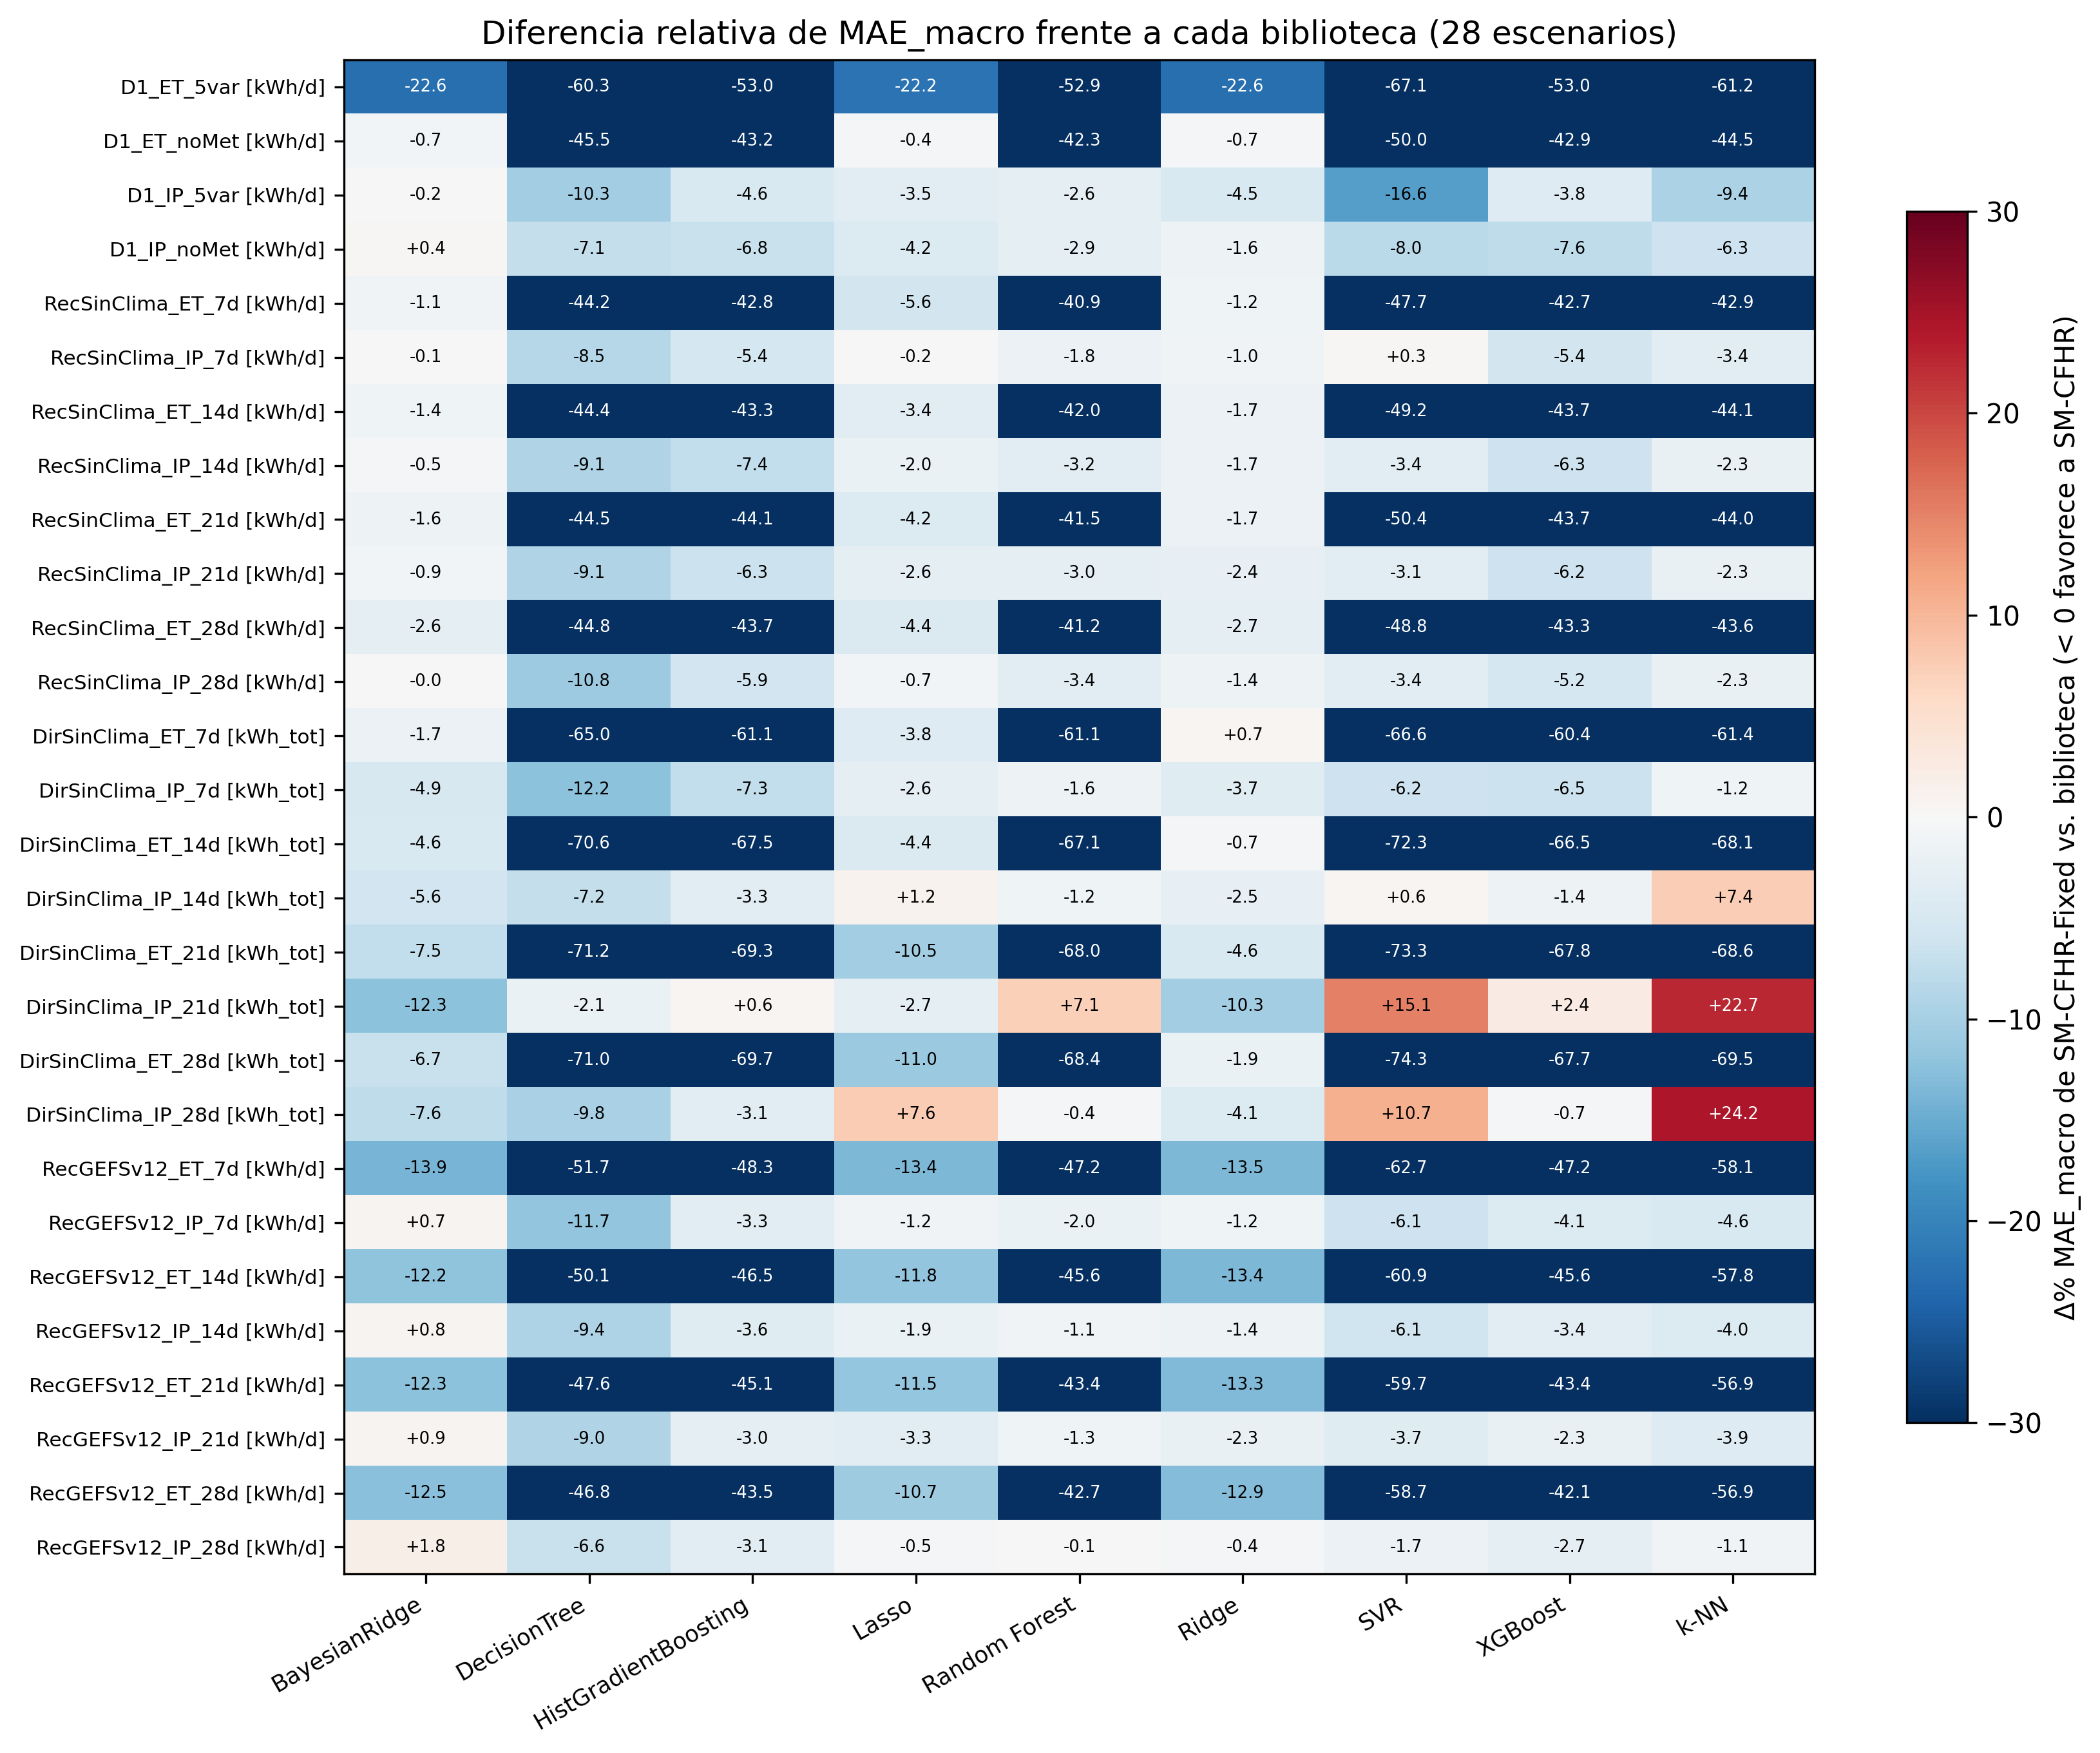

In [5]:
if ped_figs:
    display(Image(filename=str(ped_figs["P02"][0])))

Las ganancias frente a modelos no lineales y de árboles alcanzan entre `-22%` y `-58%` en `D+1` y `RecGEFSv12`. Las desventajas se concentran en `DirectoSinClima_intraplanta` (frente a `k-NN`, `Random Forest` y `SVR`) y en diferencias menores (`+0.7%` a `+1.8%`) frente a `BayesianRidge` en `RecGEFSv12_intraplanta`.

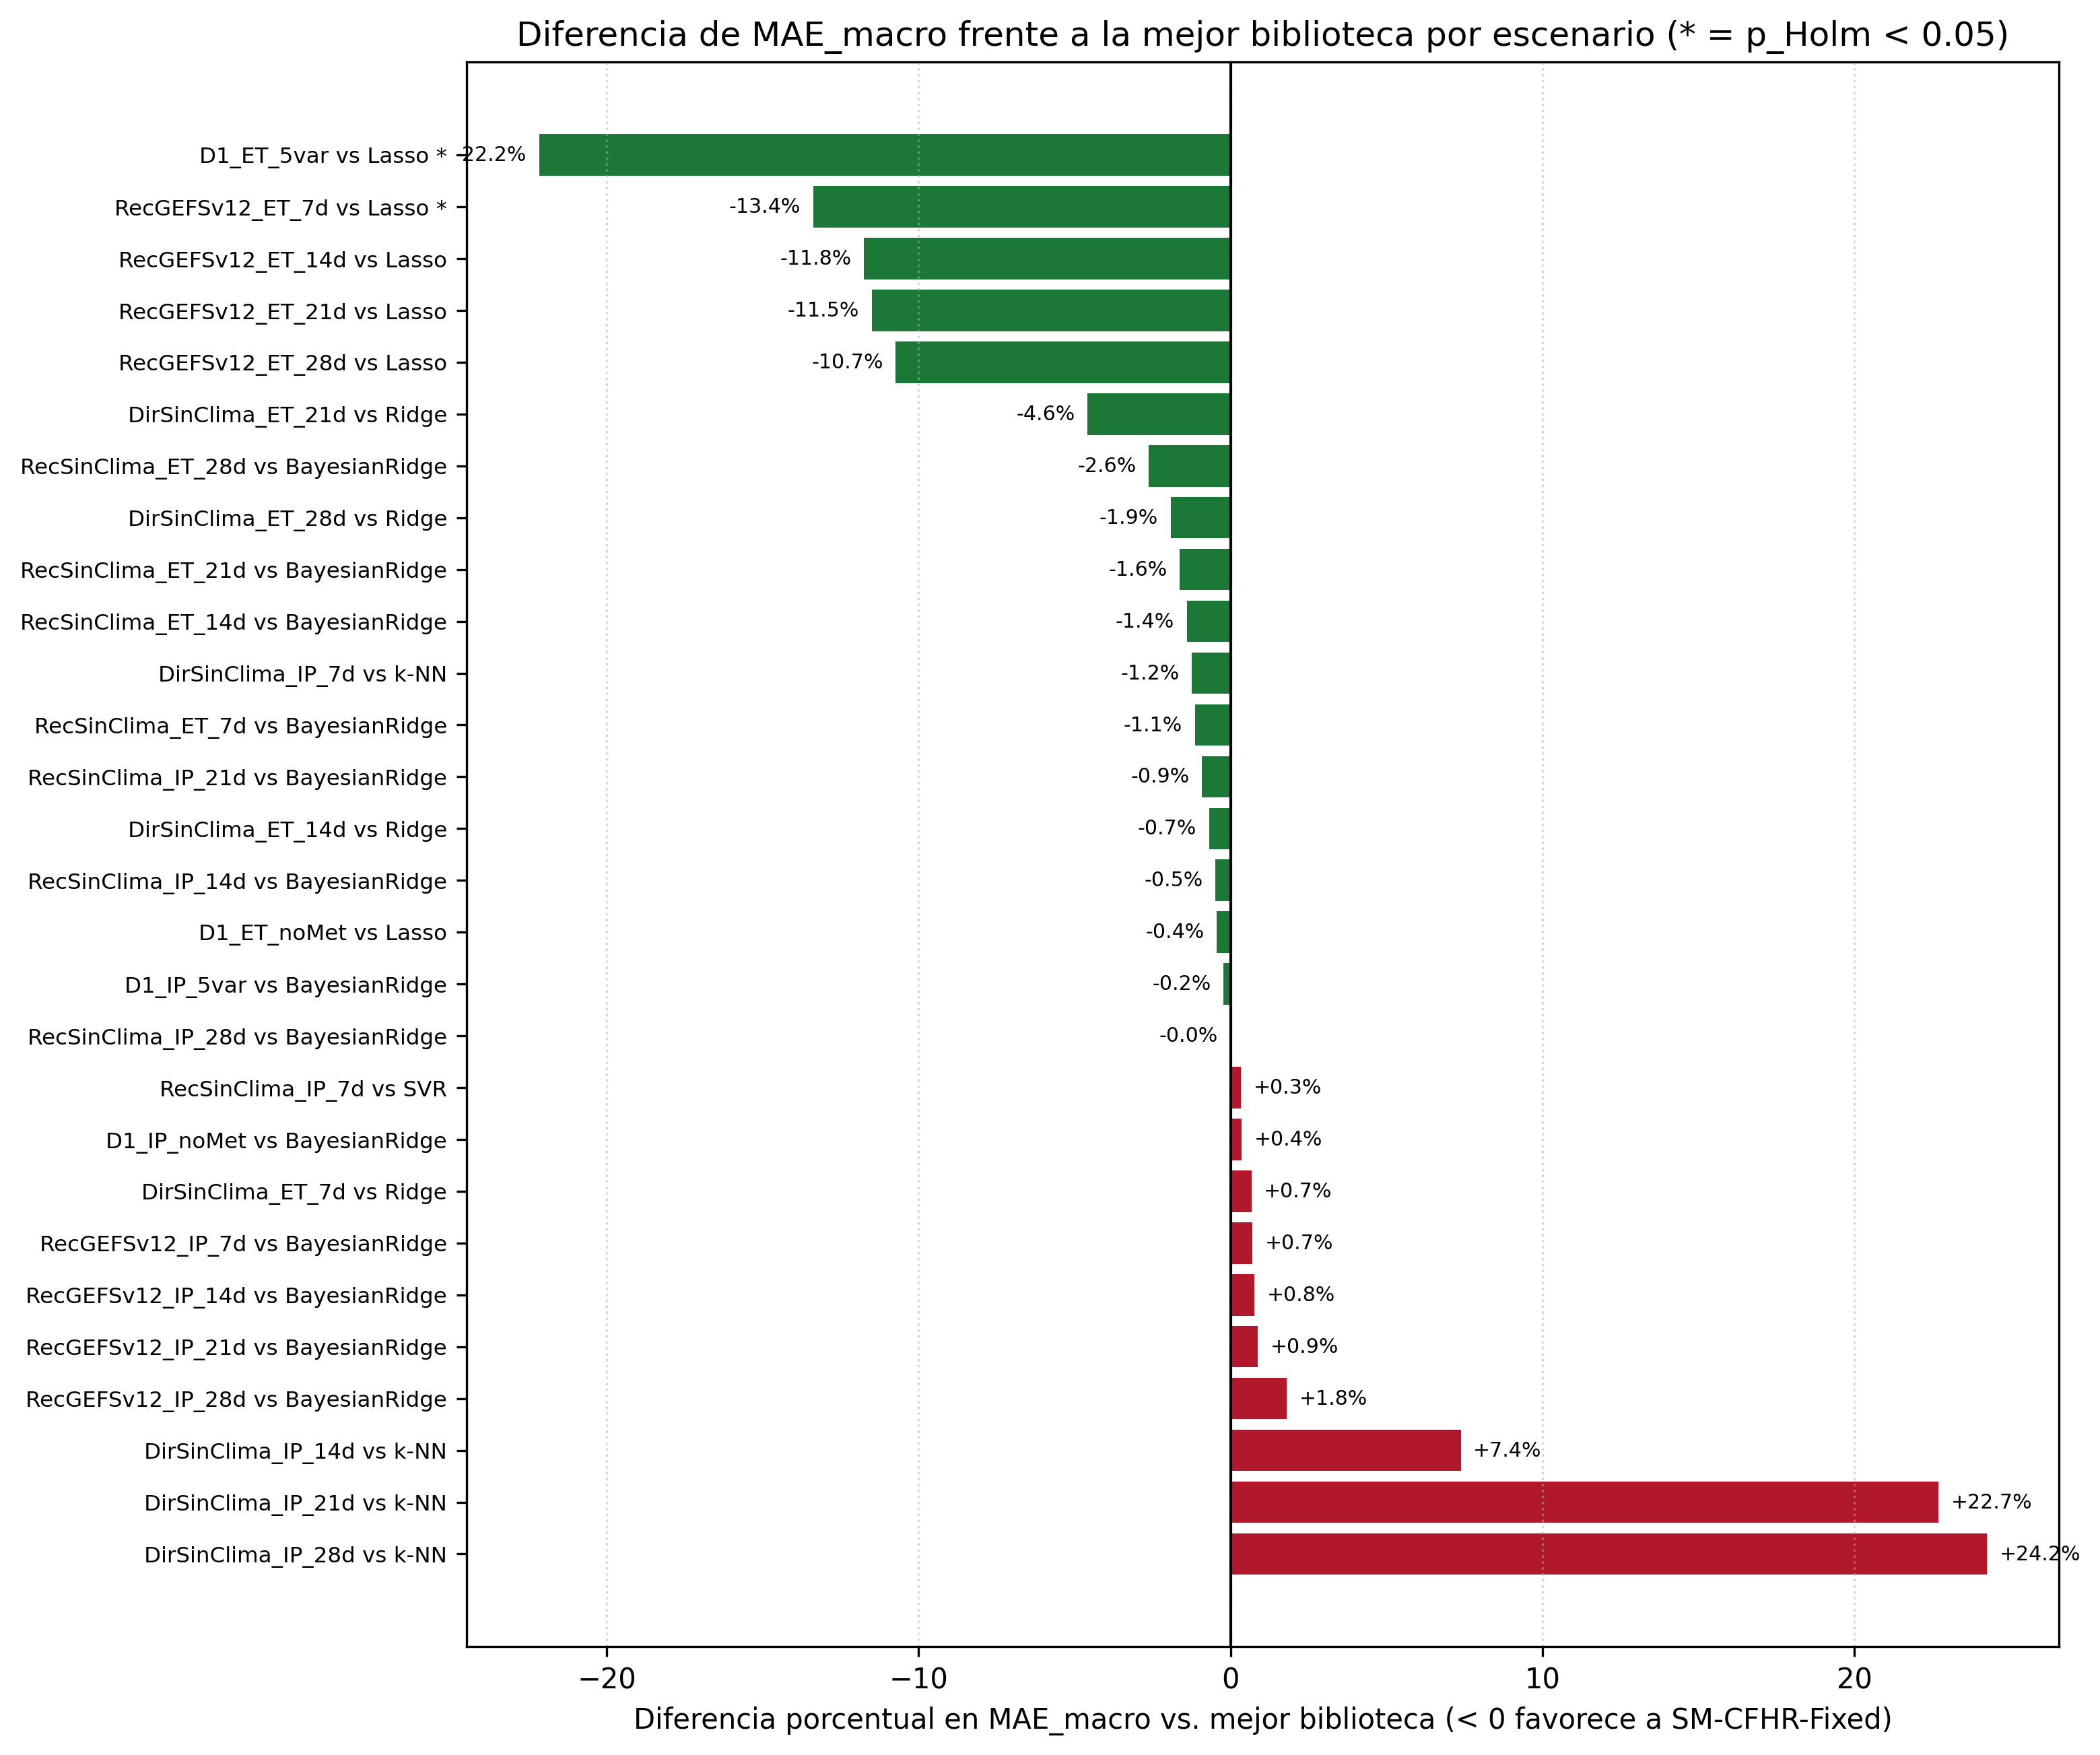

In [6]:
if ped_figs:
    display(Image(filename=str(ped_figs["P03"][0])))

Frente a la mejor biblioteca de cada escenario (seleccionada *ex post*), `SM-CFHR-Fixed` obtiene menor `MAE_macro` en **`18/28` escenarios** (hasta `-22.16%` en `D1_ET_5var` y `-13.38%` en `RecGEFSv12_ET_7d`) y pierde en **`10/28`**. Seis de esas diez derrotas son menores al `2%`, pero tres superan el `+7%` en `DirectoSinClima_IP` (hasta `+24.24%` frente a `k-NN`).

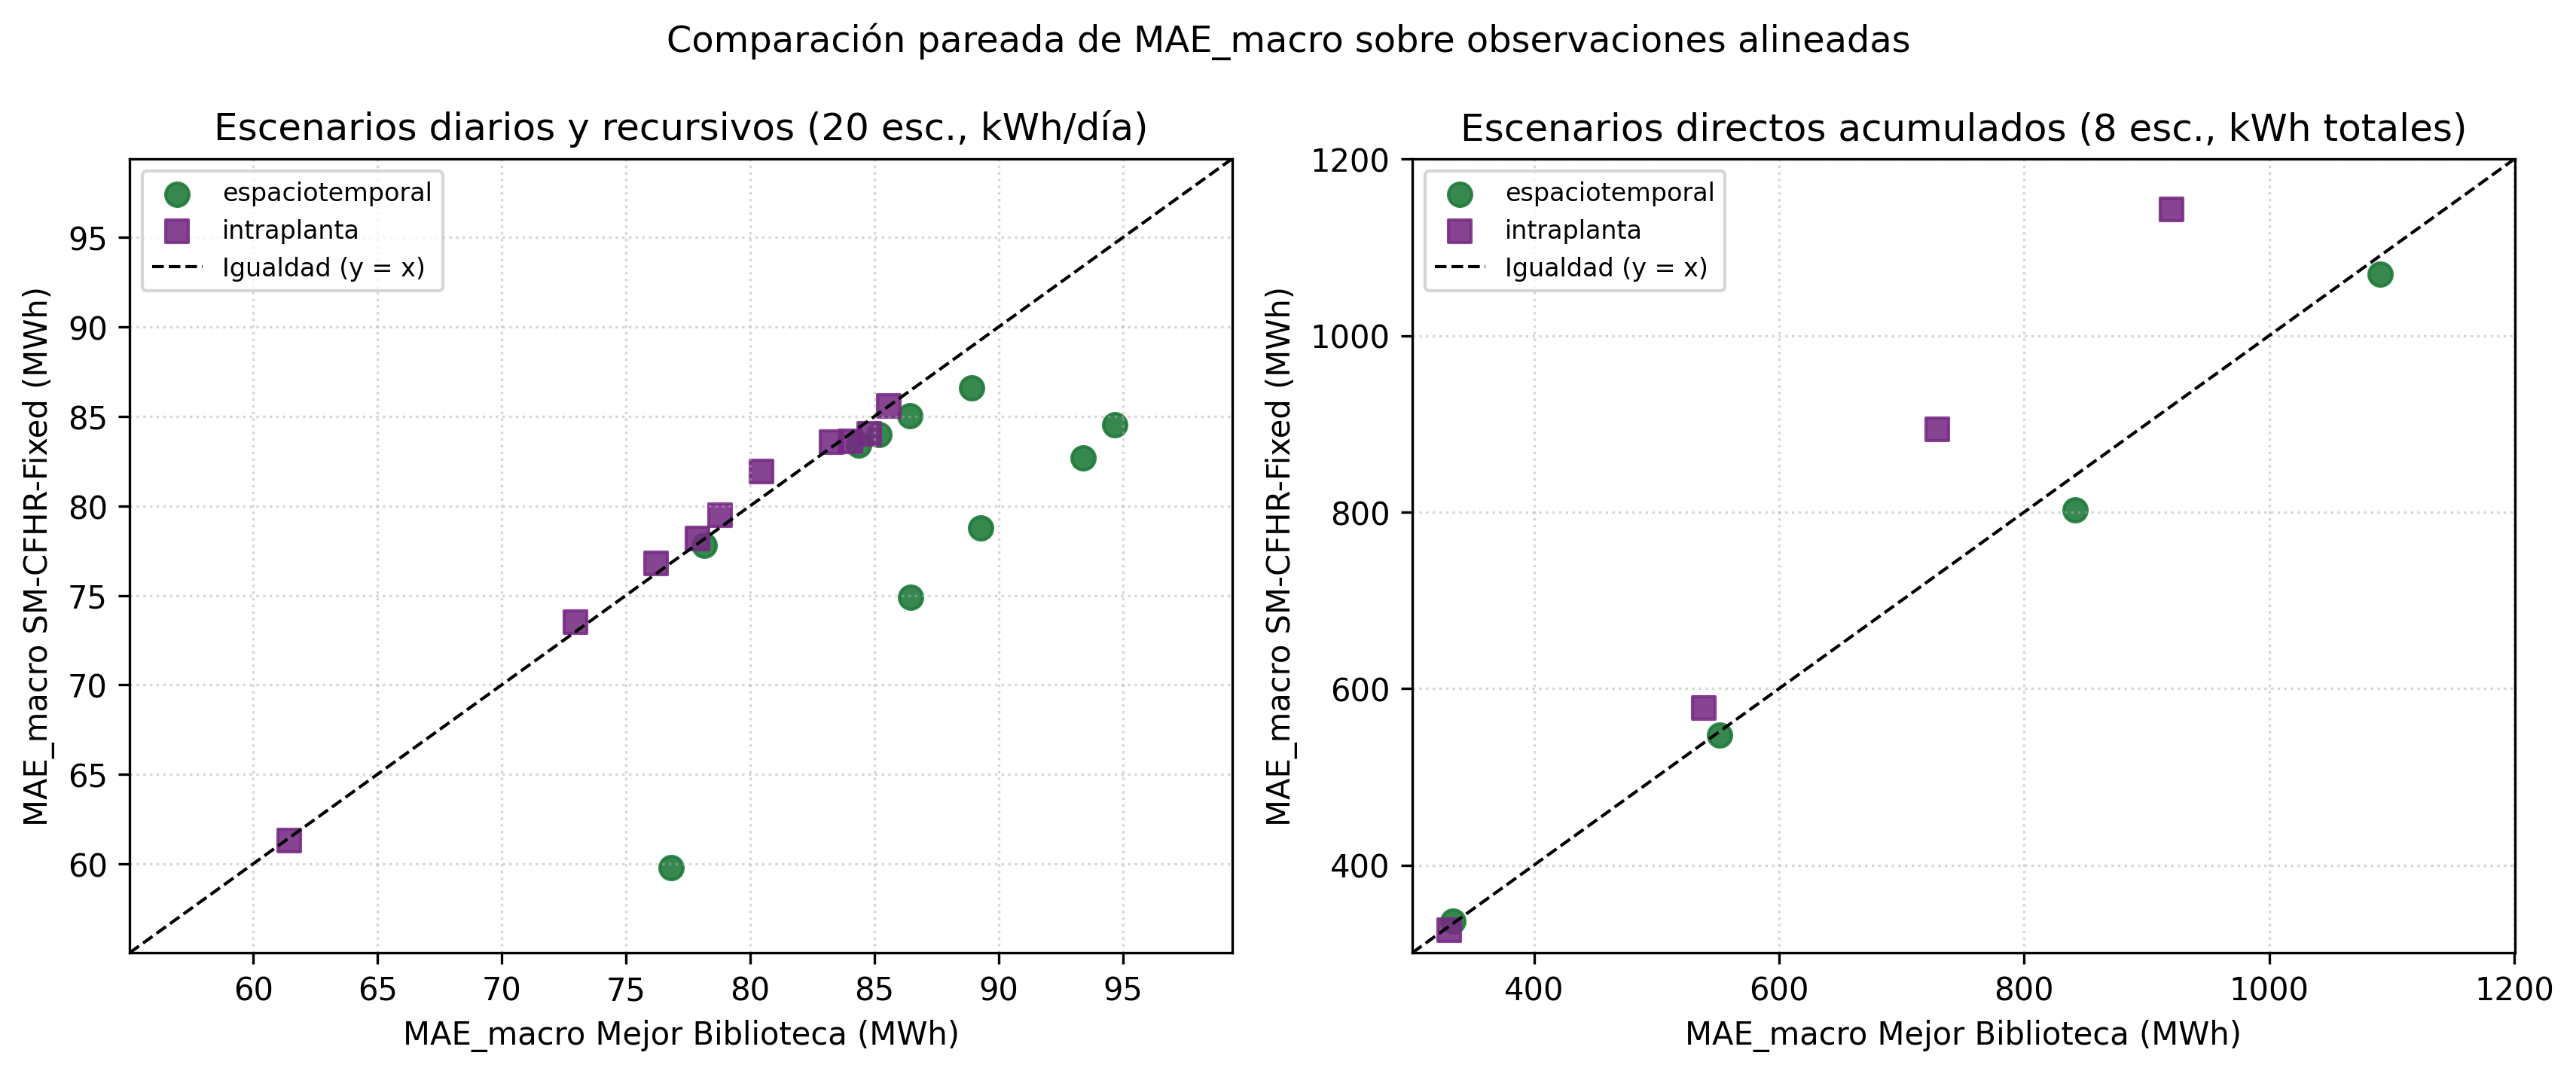

In [7]:
if ped_figs:
    display(Image(filename=str(ped_figs["P04"][0])))

Al separar las escalas de medición (`kWh/día` en `20` escenarios diarios/recursivos y `kWh_total` en `8` directos acumulados), los escenarios espaciotemporales (`ET`) se ubican por debajo de la diagonal de igualdad en ambas escalas, mientras los escenarios intraplanta (`IP`) se mantienen próximos a la diagonal o por encima en el régimen directo.

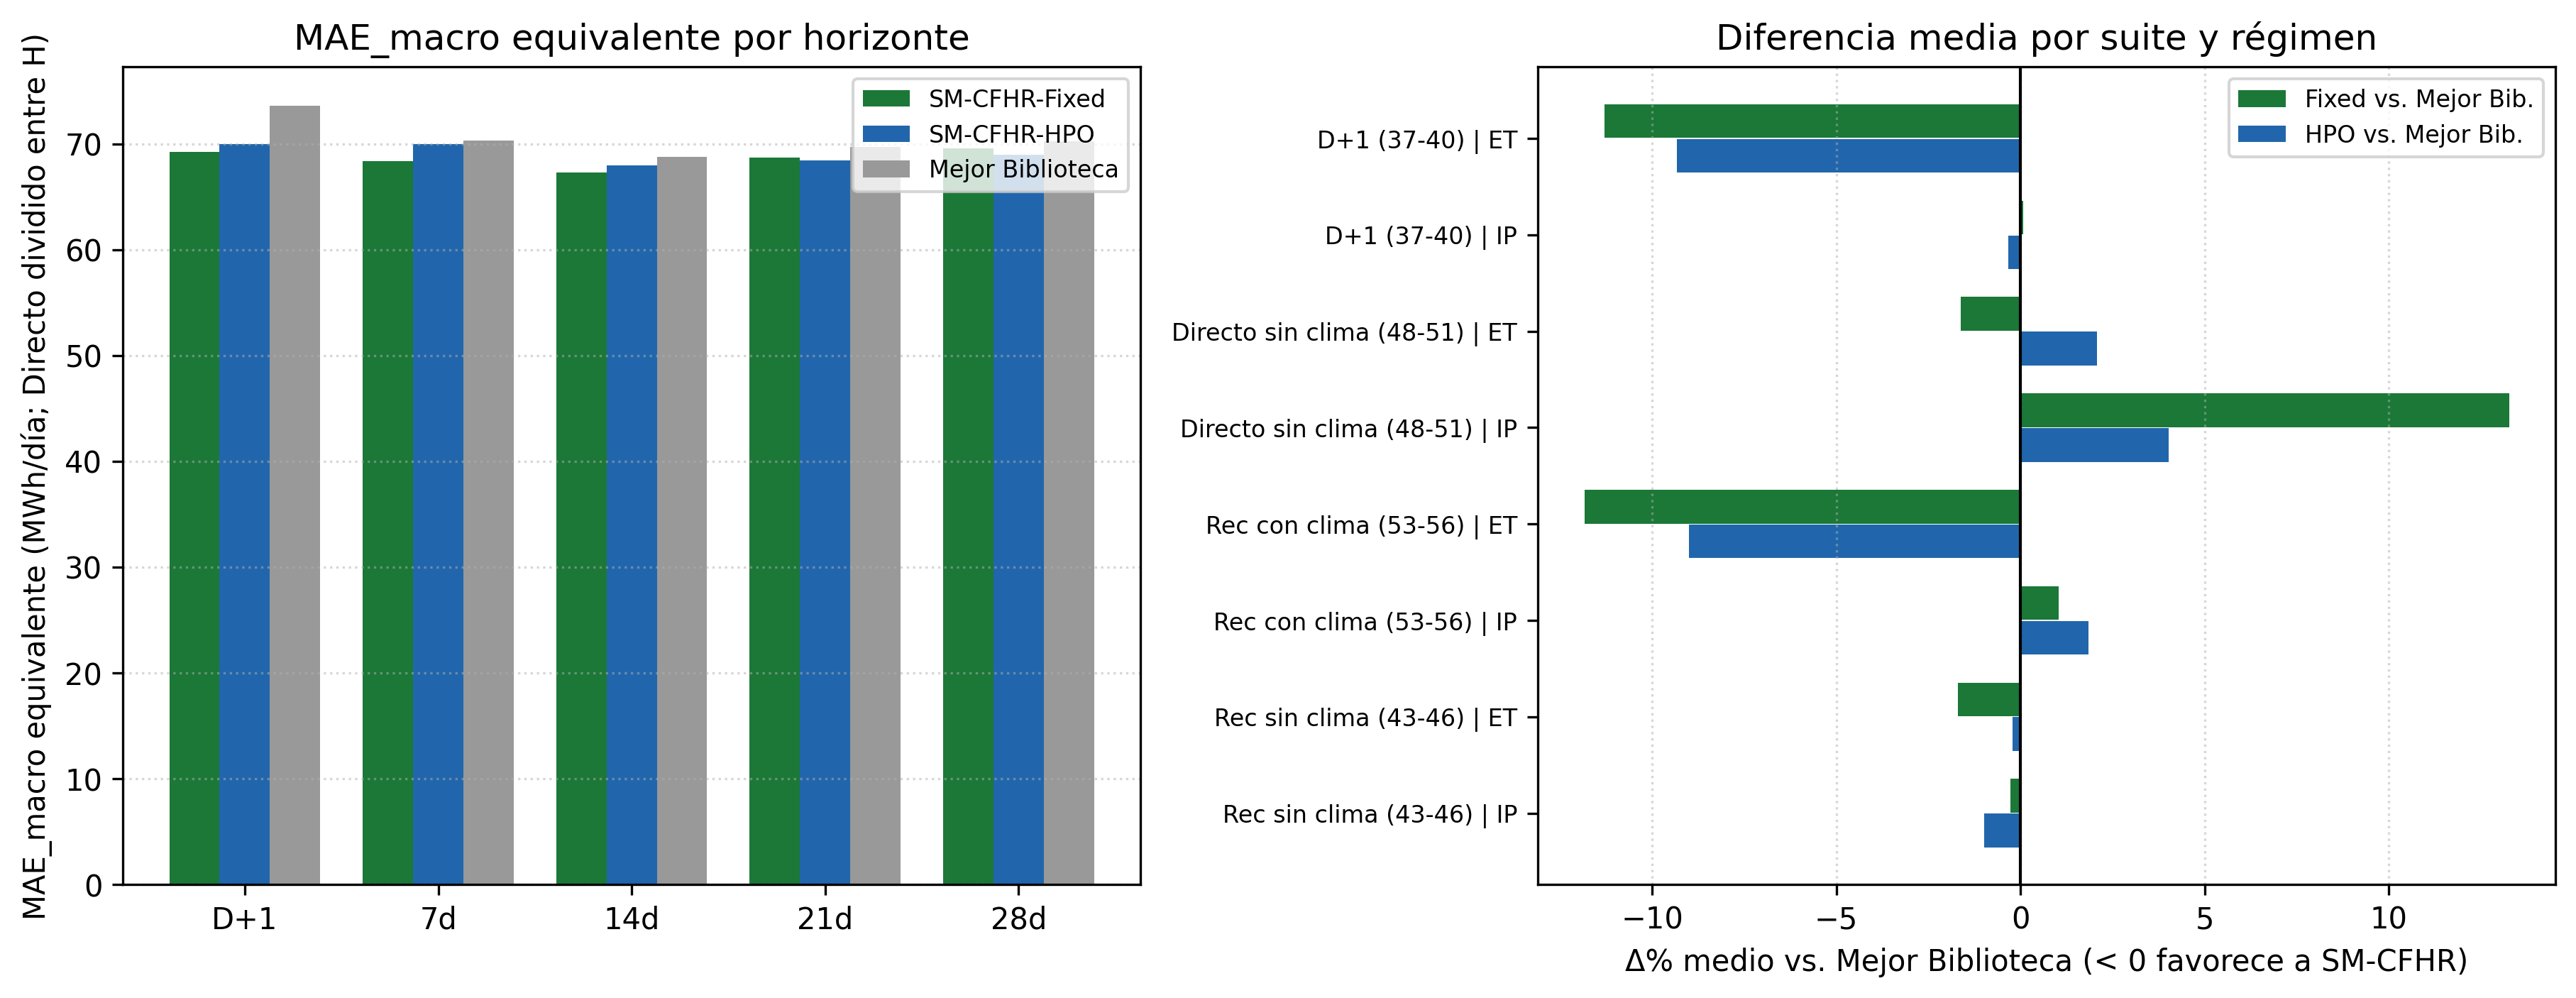

In [8]:
if ped_figs:
    display(Image(filename=str(ped_figs["P05"][0])))

La inclusión de pronósticos `GEFSv12` mantiene el error diario equivalente más bajo de `7` a `28` días. Al promediar por suite y régimen, `SM-CFHR-Fixed` mejora a `Mejor_Bib` en todas las suites espaciotemporales (`-11.30%` en `D+1 ET` y `-11.84%` en `Rec+GEFSv12 ET`), mientras que `Directo sin clima IP` registra un deterioro medio de `+13.27%`.

# Capítulo 4. Evaluación general sobre 23 modelos, inferencia estadística y criterios R3

Se evalúa el desempeño frente al conjunto completo de `22` competidores oficiales (incluyendo `12` modelos *custom* y `MM30`) y el cumplimiento formal de los criterios R3 congelados.

,suite,task,n_escenarios,rango_medio,victorias_vs_bib,victorias_vs_custom,victorias_vs_mm30,pct_medio_vs_bib
0,D+1 (37-40),espaciotemporal,2,1.00,2,2,2,-11.300467
1,D+1 (37-40),intraplanta,2,7.50,1,0,2,0.068939
2,Directo sin clima (48-51),espaciotemporal,4,3.25,3,3,0,-1.629684
3,Directo sin clima (48-51),intraplanta,4,6.50,1,1,0,13.268070
4,Rec con clima (53-56),espaciotemporal,4,1.00,4,4,4,-11.841720
5,Rec con clima (53-56),intraplanta,4,2.00,0,4,4,1.037242
6,Rec sin clima (43-46),espaciotemporal,4,2.00,4,4,0,-1.697857
7,Rec sin clima (43-46),intraplanta,4,1.50,3,4,3,-0.269327


,condicion,estado,evidencia,resultado
0,Condicion_1_Metrica_Externa,NO_CUMPLE,Victorias vs Mejor Biblioteca: 18/28 escenarios,18/28
1,Condicion_2_Pruebas_Multiples_y_MCS,NO_CUMPLE,"DM-HLN Holm=2/15, MCS_excl=1/28, SPA_sig=8/28","Holm=2, MCS_excl=1"
2,Condicion_3_Tamano_Efecto,NO_CUMPLE,|Cohen's d| >= 0.2 en 2/15 escenarios con T_ef...,2/15
3,Condicion_4_Alcance_y_Consistencia,PENDIENTE_AUTORIZACION,28 escenarios solares (17 plantas Colombia); s...,PENDIENTE_AUTORIZACION


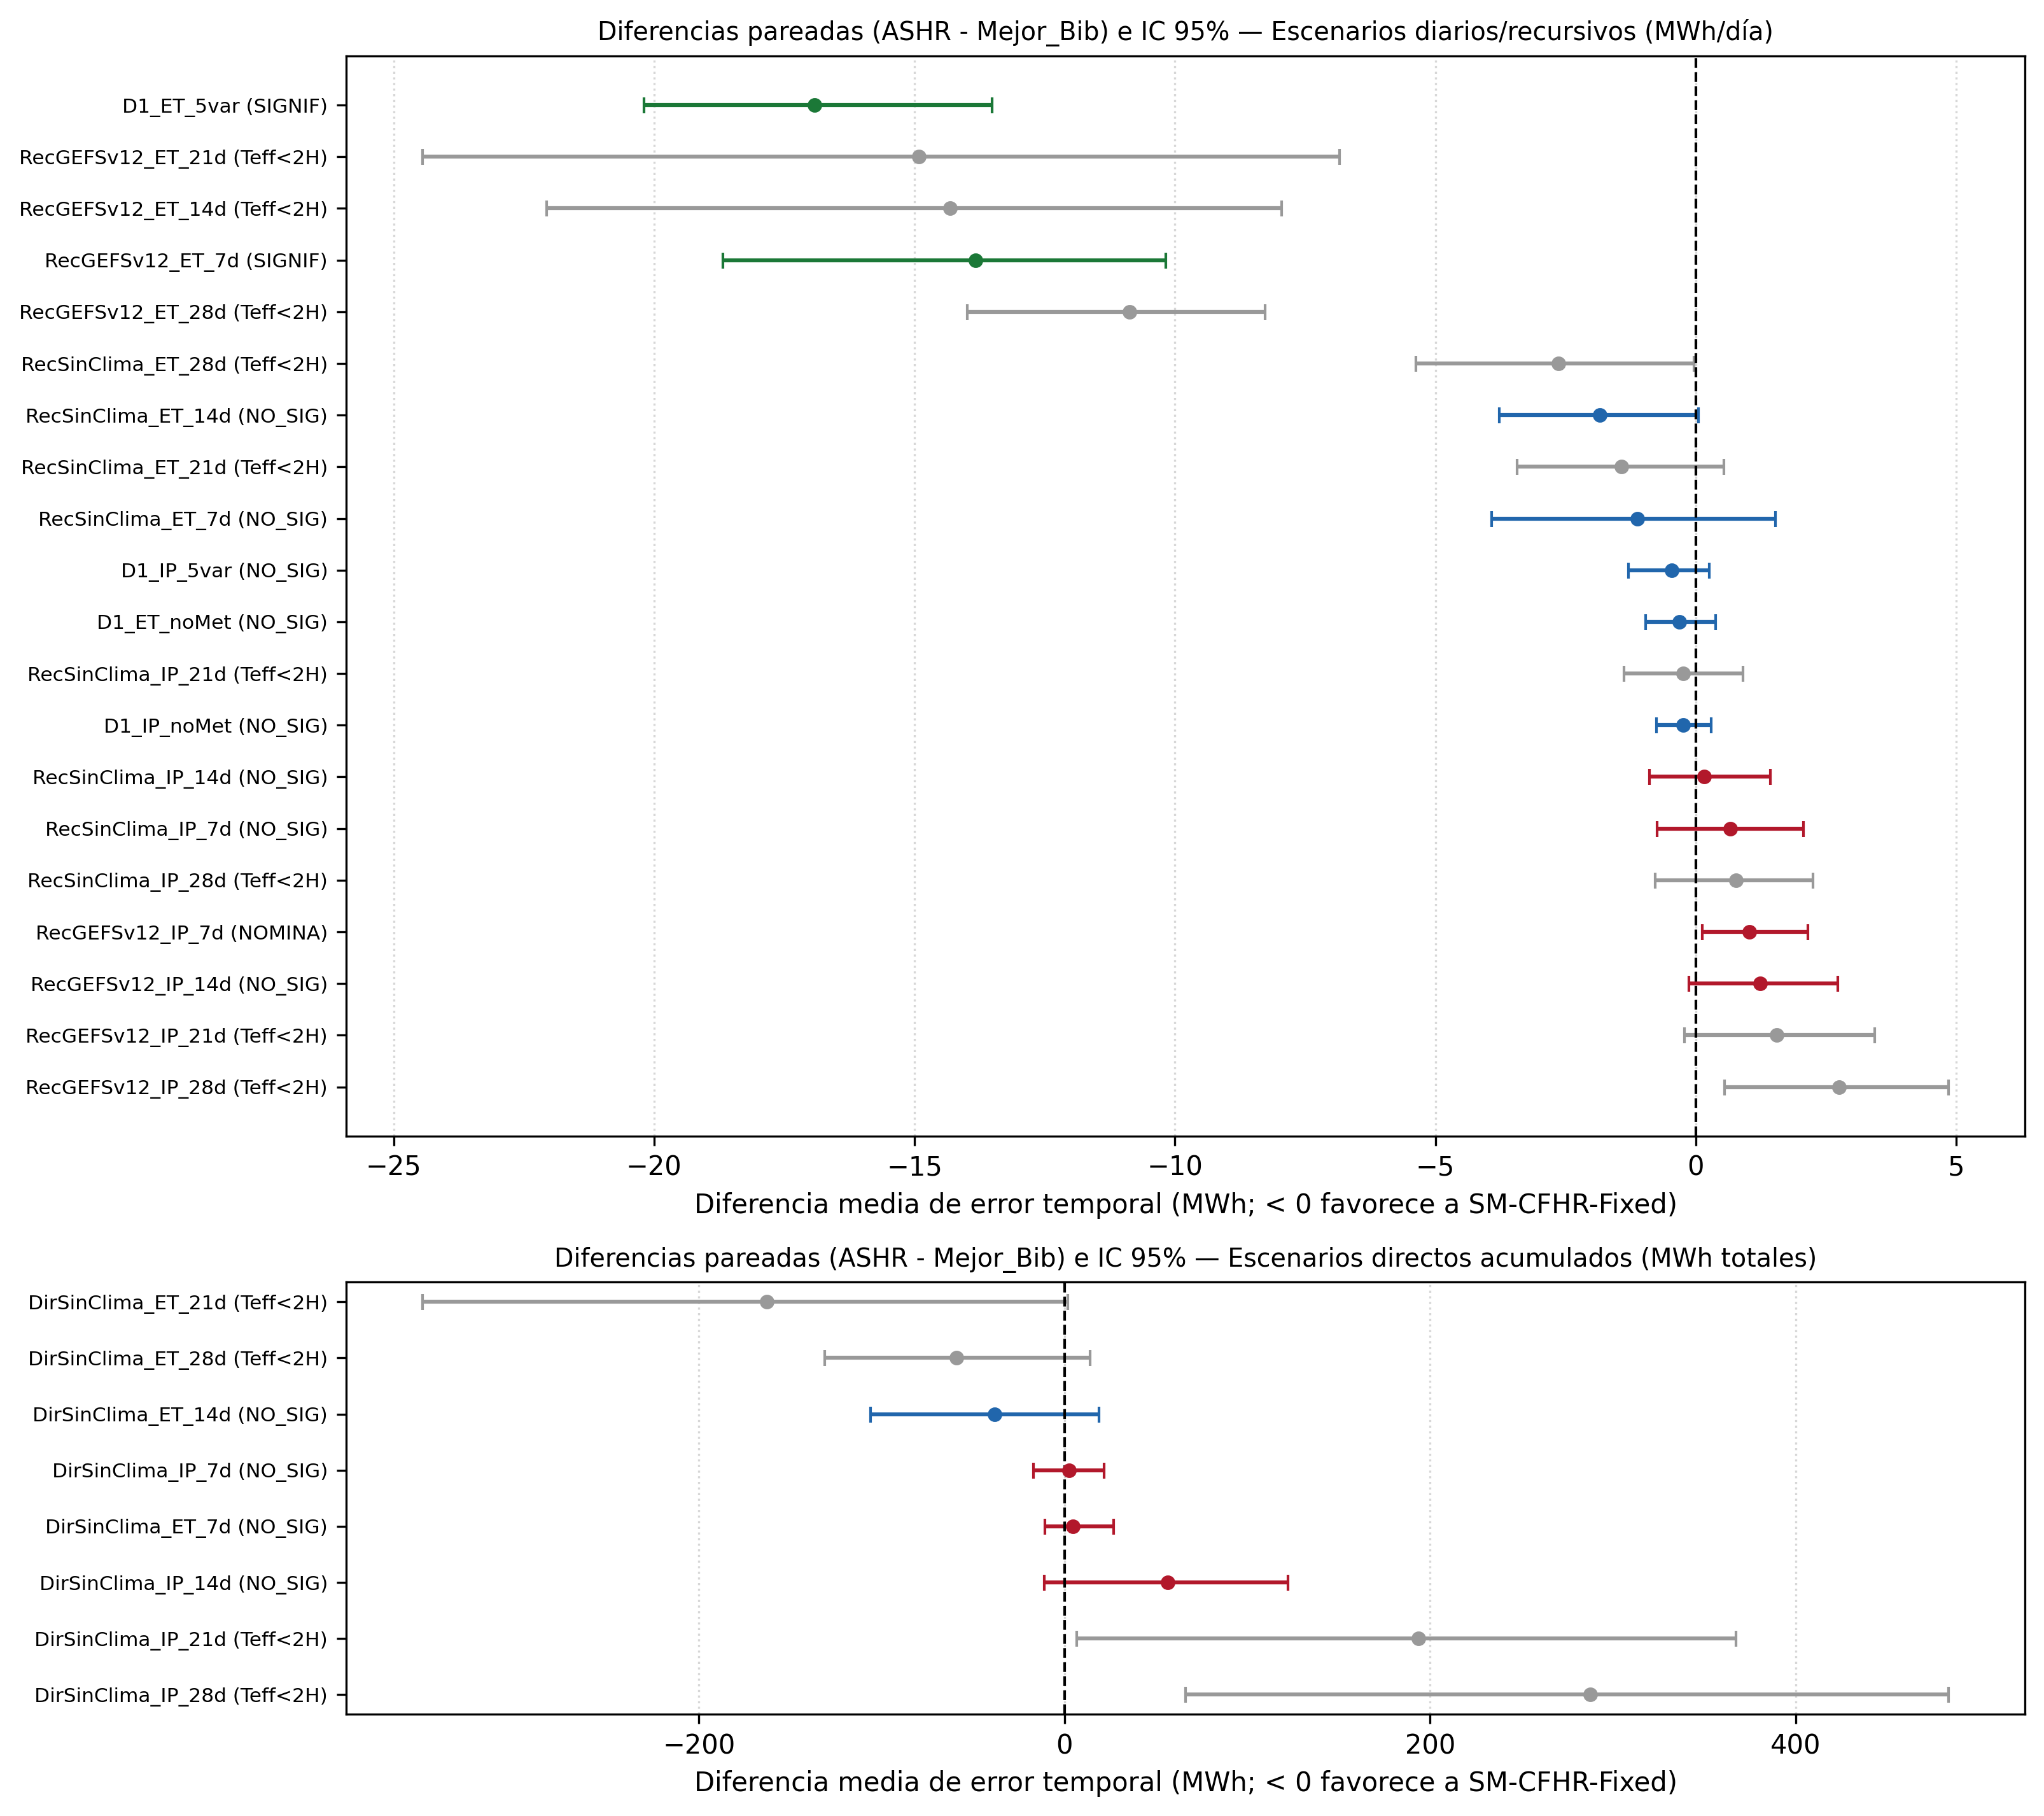

En el ranking sobre `23` modelos, `SM-CFHR-Fixed` alcanza un rango medio global de `2.93/23` (`18/28` victorias frente a `Mejor_Bib` y `22/28` frente al mejor modelo *custom*). Bajo el protocolo congelado, `15/28` escenarios satisfacen $T_{\mathrm{eff}} \ge 2H$; dentro de ese subconjunto, **`2/15` resultan significativos tras Holm** (`D1_ET_5var` con IC `[-20.2, -13.5]` MWh/día y `RecGEFSv12_ET_7d` con IC `[-18.7, -10.2]` MWh/día) y `2/15` alcanzan $d_z \le -0{,}20$.

En consecuencia, los requisitos estrictos de R3 (`28/28` sin derrotas y mayoría significativa con efecto relevante) **no se cumplen de forma general**, acotándose la superioridad estadística demostrada al régimen espaciotemporal con clima. Nota metodológica (trazabilidad de estimandos y versión): el protocolo congelado anterior (`v1.0.3`, tabla mostrada aquí sin recalcular) evalúa `DM-HLN-HAC` sobre promedios temporales por fecha/origen (`MAE_promedio_por_origen`, unidad = origen, referencia retrospectiva `Mejor_Bib`, Holm por familia, filtro $T_{\mathrm{eff}} \ge 2H$). Una revisión independiente posterior (`v2.0.0`, documentada en `auditoria_inferencia_estadistica.ipynb` y `resultados/inferencia_revision_independiente_v2/`) reconcilió el estimando con el `MAE_macro` del ranking mediante la serie macro-alineada $z_t^{\mathrm{macro}}$ y bootstrap sincronizado, encontrando `4/28` cambios de signo en paneles desbalanceados y `5/28` victorias Holm (todos los escenarios `ET + Clima`: `D1` y `7d`–`28d`, con $T_{\mathrm{eff,macro}} \ge 30.82$), además de `MAE_CF_macro` adimensional (rango medio `4.00/23`, `16/28` victorias). Limitación: `Mejor_Bib` es una selección retrospectiva.

In [9]:
if bundle is not None:
    display(bundle["tabla_rankings_regimen"])
    r3_verdict_df = evaluate_r3_superiority(bundle, scope_authorized=SCOPE_AUTHORIZED, alpha=0.05)
    display(r3_verdict_df[["condicion", "estado", "evidencia", "resultado"]])
    display(Image(filename=str(ped_figs["P06"][0])))
    t_inf_bib = bundle["tabla_inferencia"][bundle["tabla_inferencia"]["referencia"] == "Mejor_Bib"]
    n_teff_ok = int((~t_inf_bib["t_eff_insufficient"]).sum())
    n_holm_ok = int((t_inf_bib.loc[~t_inf_bib["t_eff_insufficient"], "p_holm"] < 0.05).sum())
    display(Markdown(
        f"En el ranking sobre `23` modelos, `SM-CFHR-Fixed` alcanza un rango medio global de `2.93/23` (`18/28` victorias frente a `Mejor_Bib` y `22/28` frente al mejor modelo *custom*). "
        f"Bajo el protocolo congelado, `{n_teff_ok}/28` escenarios satisfacen $T_{{\mathrm{{eff}}}} \ge 2H$; dentro de ese subconjunto, **`{n_holm_ok}/15` resultan significativos tras Holm** (`D1_ET_5var` con IC `[-20.2, -13.5]` MWh/día y `RecGEFSv12_ET_7d` con IC `[-18.7, -10.2]` MWh/día) y `2/15` alcanzan $d_z \le -0{{,}}20$.\n\n"
        f"En consecuencia, los requisitos estrictos de R3 (`28/28` sin derrotas y mayoría significativa con efecto relevante) **no se cumplen de forma general**, acotándose la superioridad estadística demostrada al régimen espaciotemporal con clima. "
        f"Nota metodológica (trazabilidad de estimandos y versión): el protocolo congelado anterior (`v1.0.3`, tabla mostrada aquí sin recalcular) evalúa `DM-HLN-HAC` sobre promedios temporales por fecha/origen (`MAE_promedio_por_origen`, unidad = origen, referencia retrospectiva `Mejor_Bib`, Holm por familia, filtro $T_{{\mathrm{{eff}}}} \ge 2H$). Una revisión independiente posterior (`v2.0.0`, documentada en `auditoria_inferencia_estadistica.ipynb` y `resultados/inferencia_revision_independiente_v2/`) reconcilió el estimando con el `MAE_macro` del ranking mediante la serie macro-alineada $z_t^{{\mathrm{{macro}}}}$ y bootstrap sincronizado, encontrando `4/28` cambios de signo en paneles desbalanceados y `5/28` victorias Holm (todos los escenarios `ET + Clima`: `D1` y `7d`–`28d`, con $T_{{\mathrm{{eff,macro}}}} \ge 30.82$), además de `MAE_CF_macro` adimensional (rango medio `4.00/23`, `16/28` victorias). Limitación: `Mejor_Bib` es una selección retrospectiva."
    ))

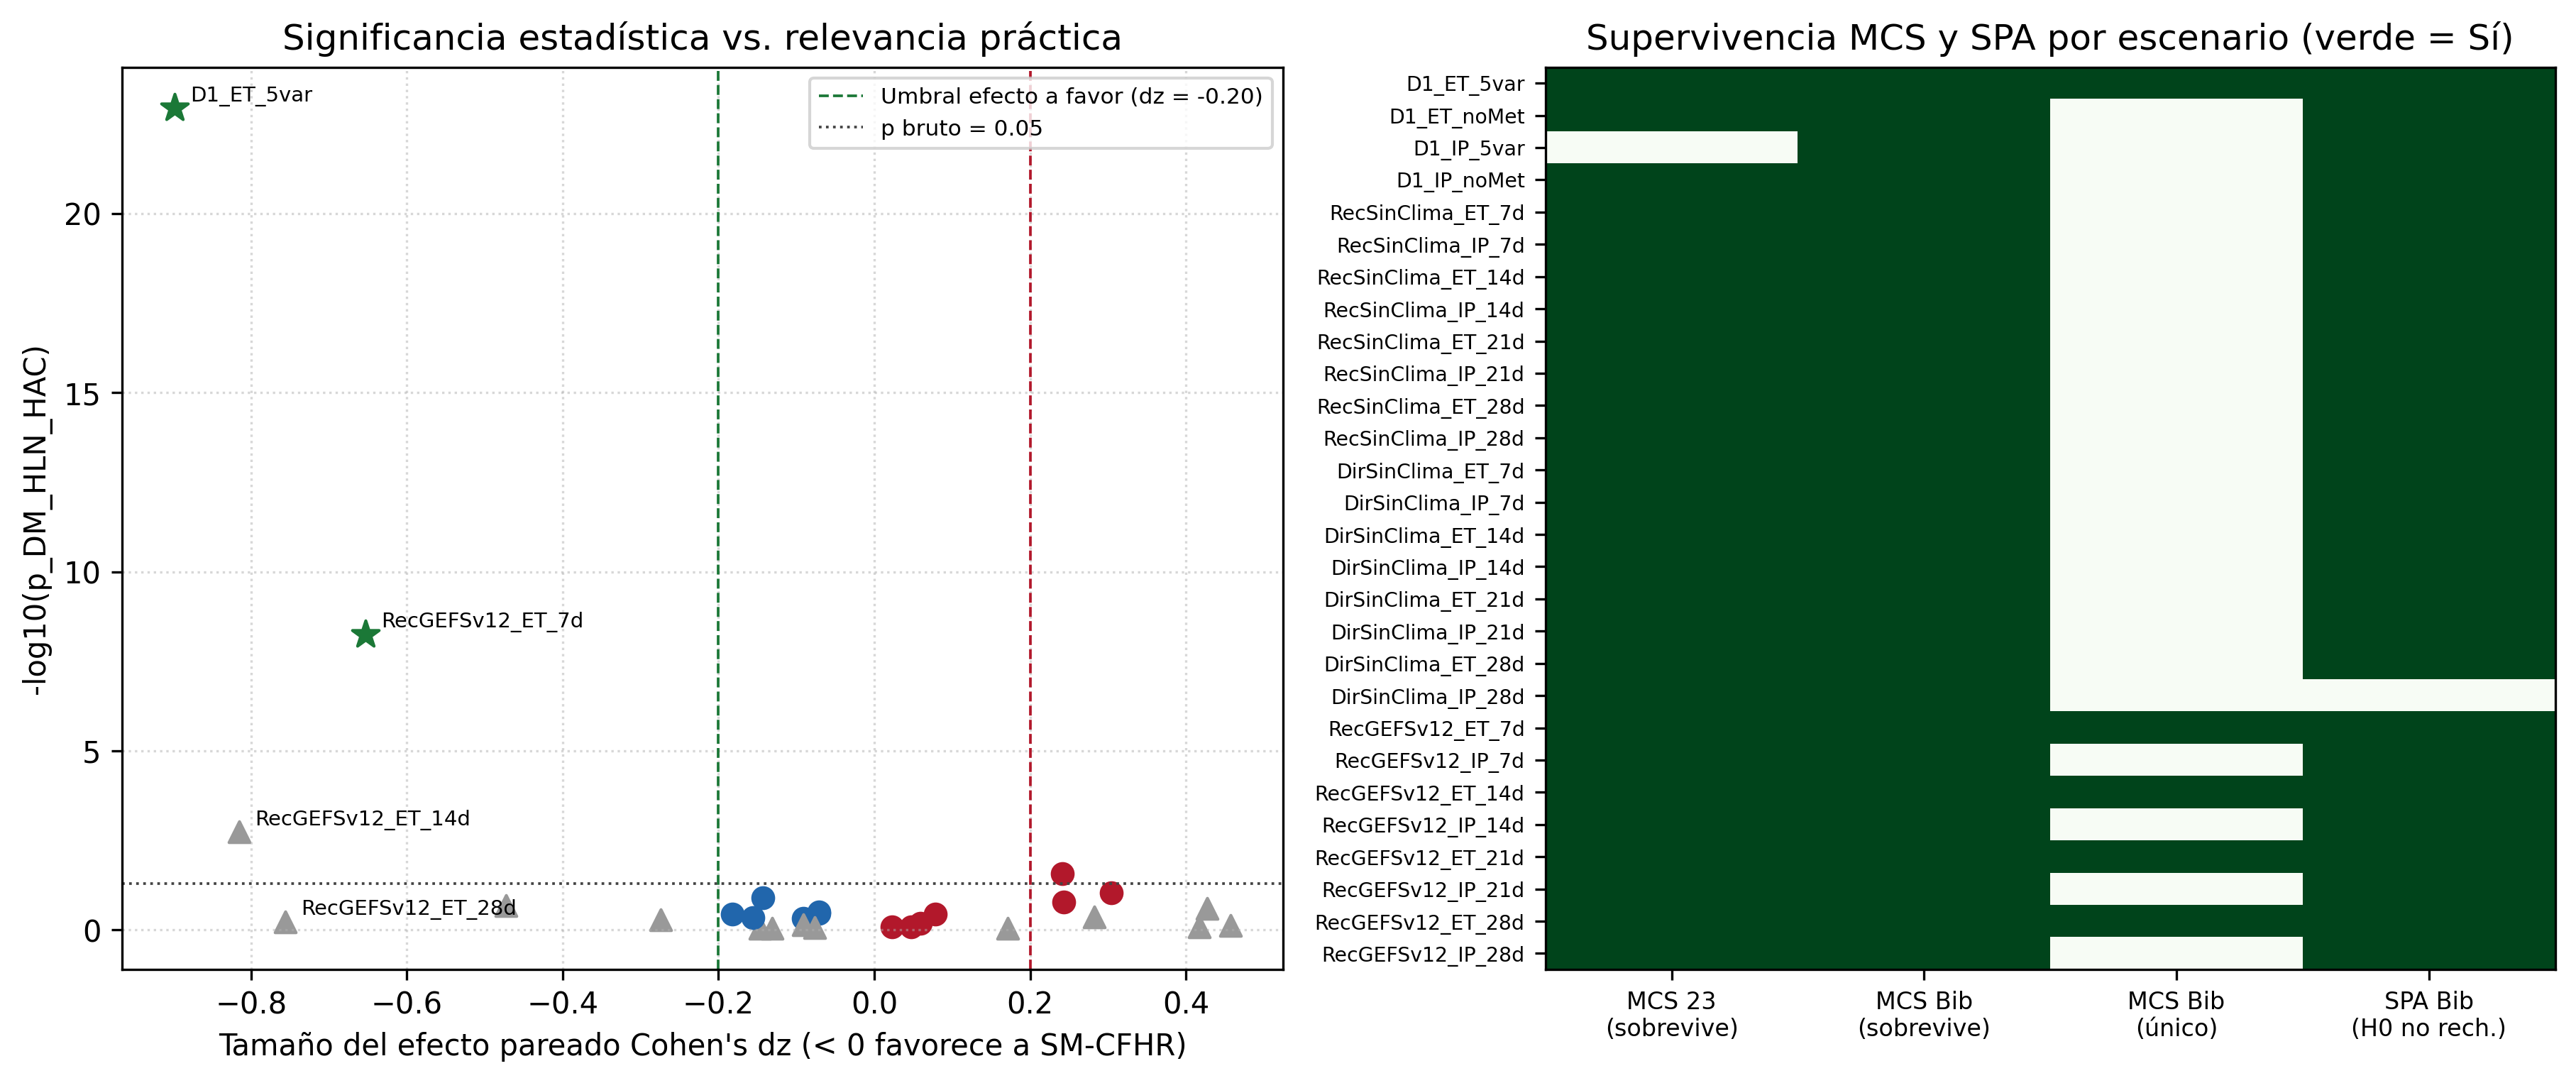

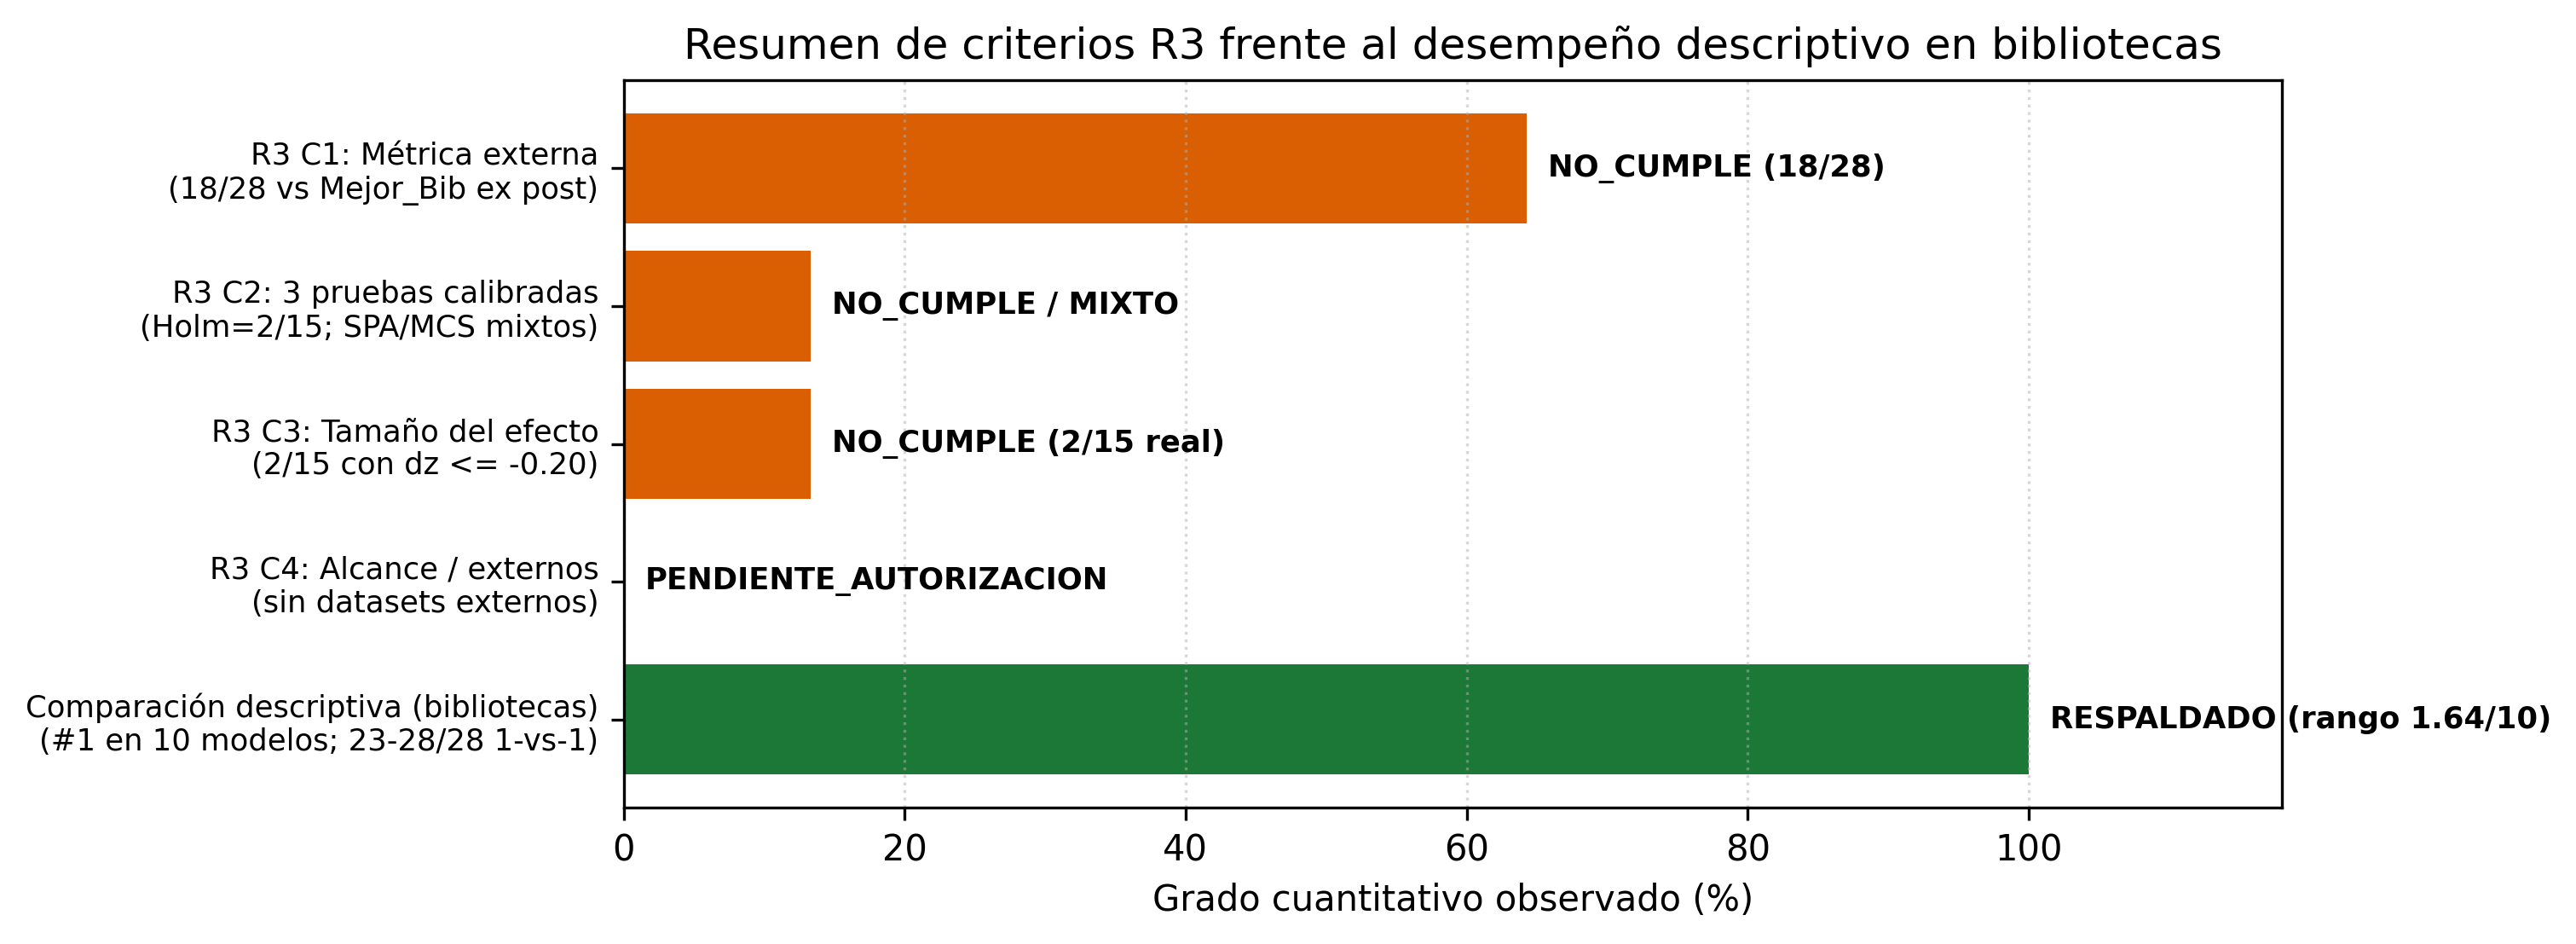

In [10]:
if ped_figs:
    display(Image(filename=str(ped_figs["P07"][0])))
    display(Image(filename=str(ped_figs["P10"][0])))

Solo `2/15` escenarios evaluables (`D1_ET_5var` con $d_z=-0{,}898$ y `RecGEFSv12_ET_7d` con $d_z=-0{,}653$) superan simultáneamente el umbral de Holm y $|d_z| \ge 0{,}20$ (`RecGEFSv12_ET_14d` alcanza $d_z=-0{,}815$, pero queda excluido por el filtro original $T_{\mathrm{eff}}=25{,}5<28$). Aunque `SM-CFHR-Fixed` permanece en el MCS general en `27/28` escenarios y en el MCS de bibliotecas en `28/28` (`4/28` como único superviviente), la permanencia en el MCS refleja no descartabilidad al `10%` y no equivale a superioridad pareada en todos los horizontes.

# Capítulo 5. Análisis intra-dataset por planta, capacidad, bloque temporal y estrategia

Se examina el comportamiento interno de `SM-CFHR-Fixed` según planta solar, capacidad instalada (`MW`), bloque temporal (`D1`–`D3`), disponibilidad de pronóstico meteorológico y estrategia recursiva frente a directa.

,code,grupo,cap_MW_media,MAE_kWh_ASHR,MAE_kWh_MejorBib,MAE_CF_ASHR,MAE_CF_MejorBib,victorias_vs_MM30_en_28
10,3K8E,6,19.900000,11765.580322,36796.740634,0.024635,0.077045,17
9,3K8C,6,19.900000,12020.985677,36979.784873,0.025170,0.077428,18
5,3IQA,4,35.000000,22860.375841,29966.156190,0.027215,0.035674,15
14,GYPO,6,371.461417,268908.221258,368764.355297,0.030163,0.041364,15
4,3INX,6,50.000000,36966.031674,38515.617442,0.030805,0.032096,20
13,EPFV,5,68.118834,51250.874080,51439.598615,0.031349,0.031464,12
11,4RGG,6,19.900000,15324.509138,31255.536861,0.032086,0.065443,23
3,3HF5,6,98.500000,78998.217530,85187.578460,0.033417,0.036035,21


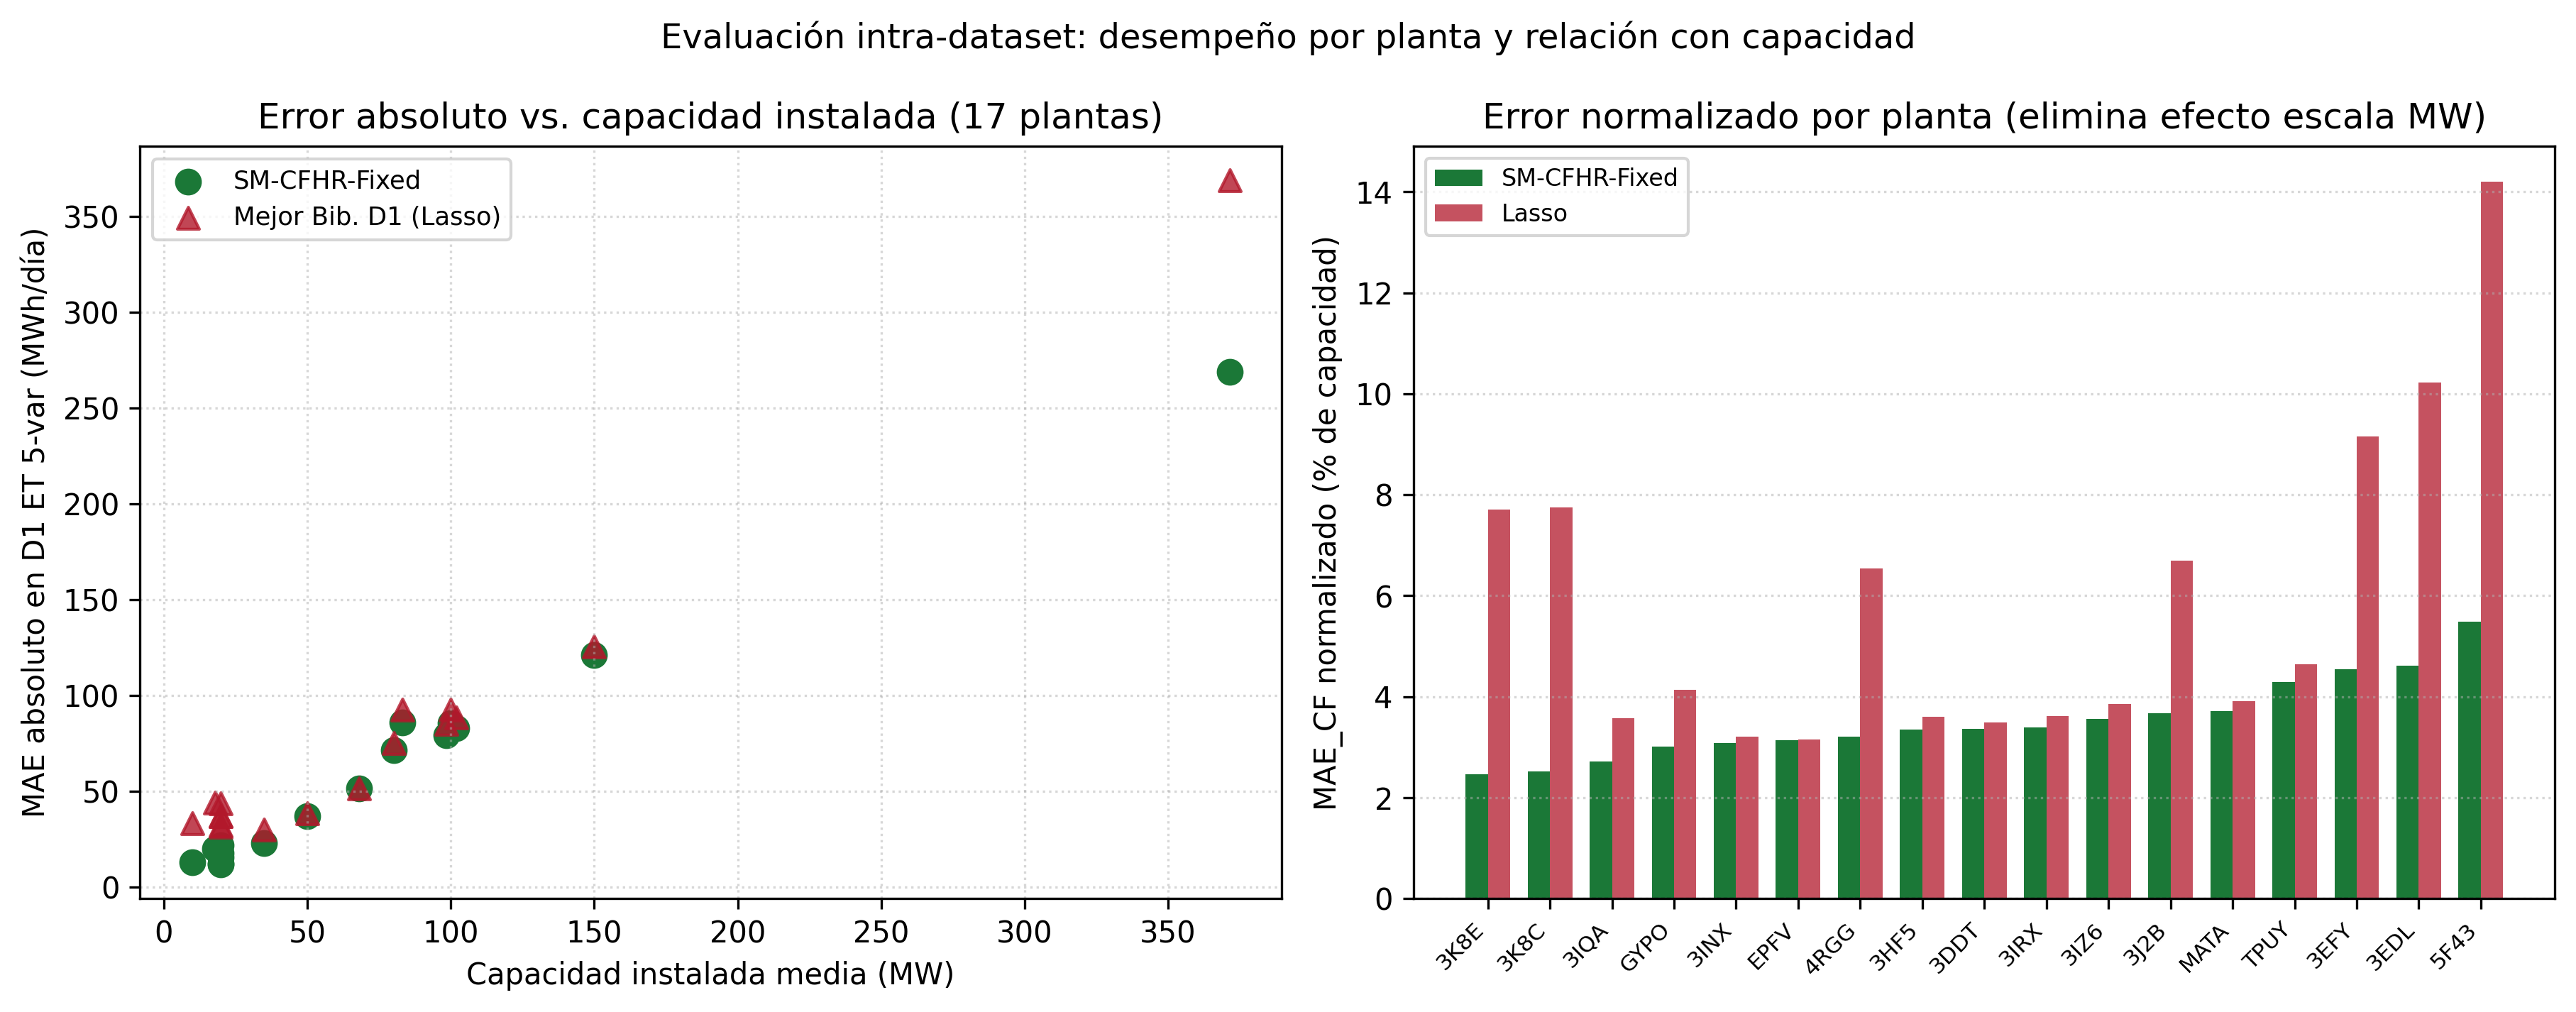

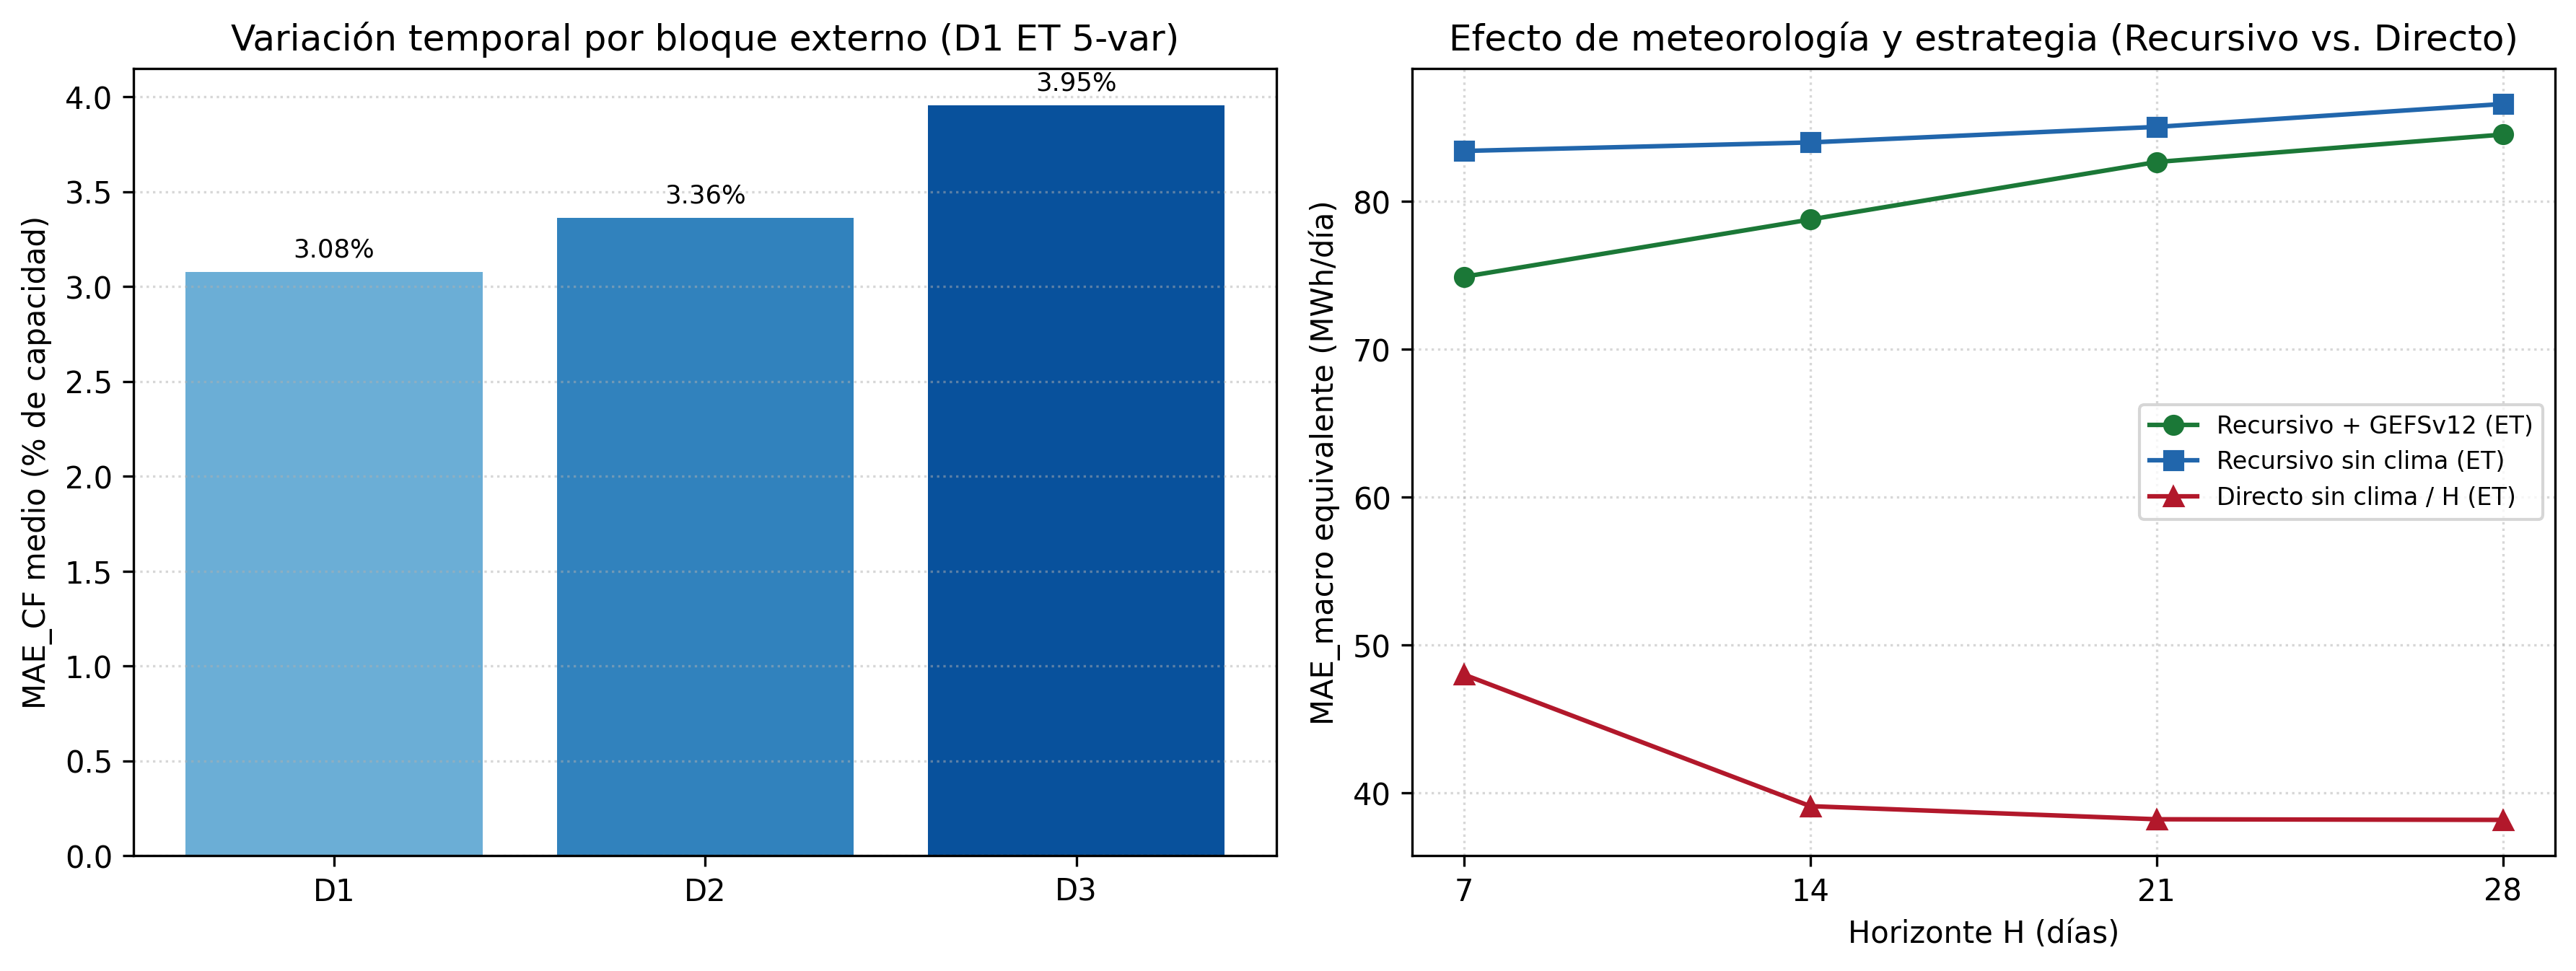

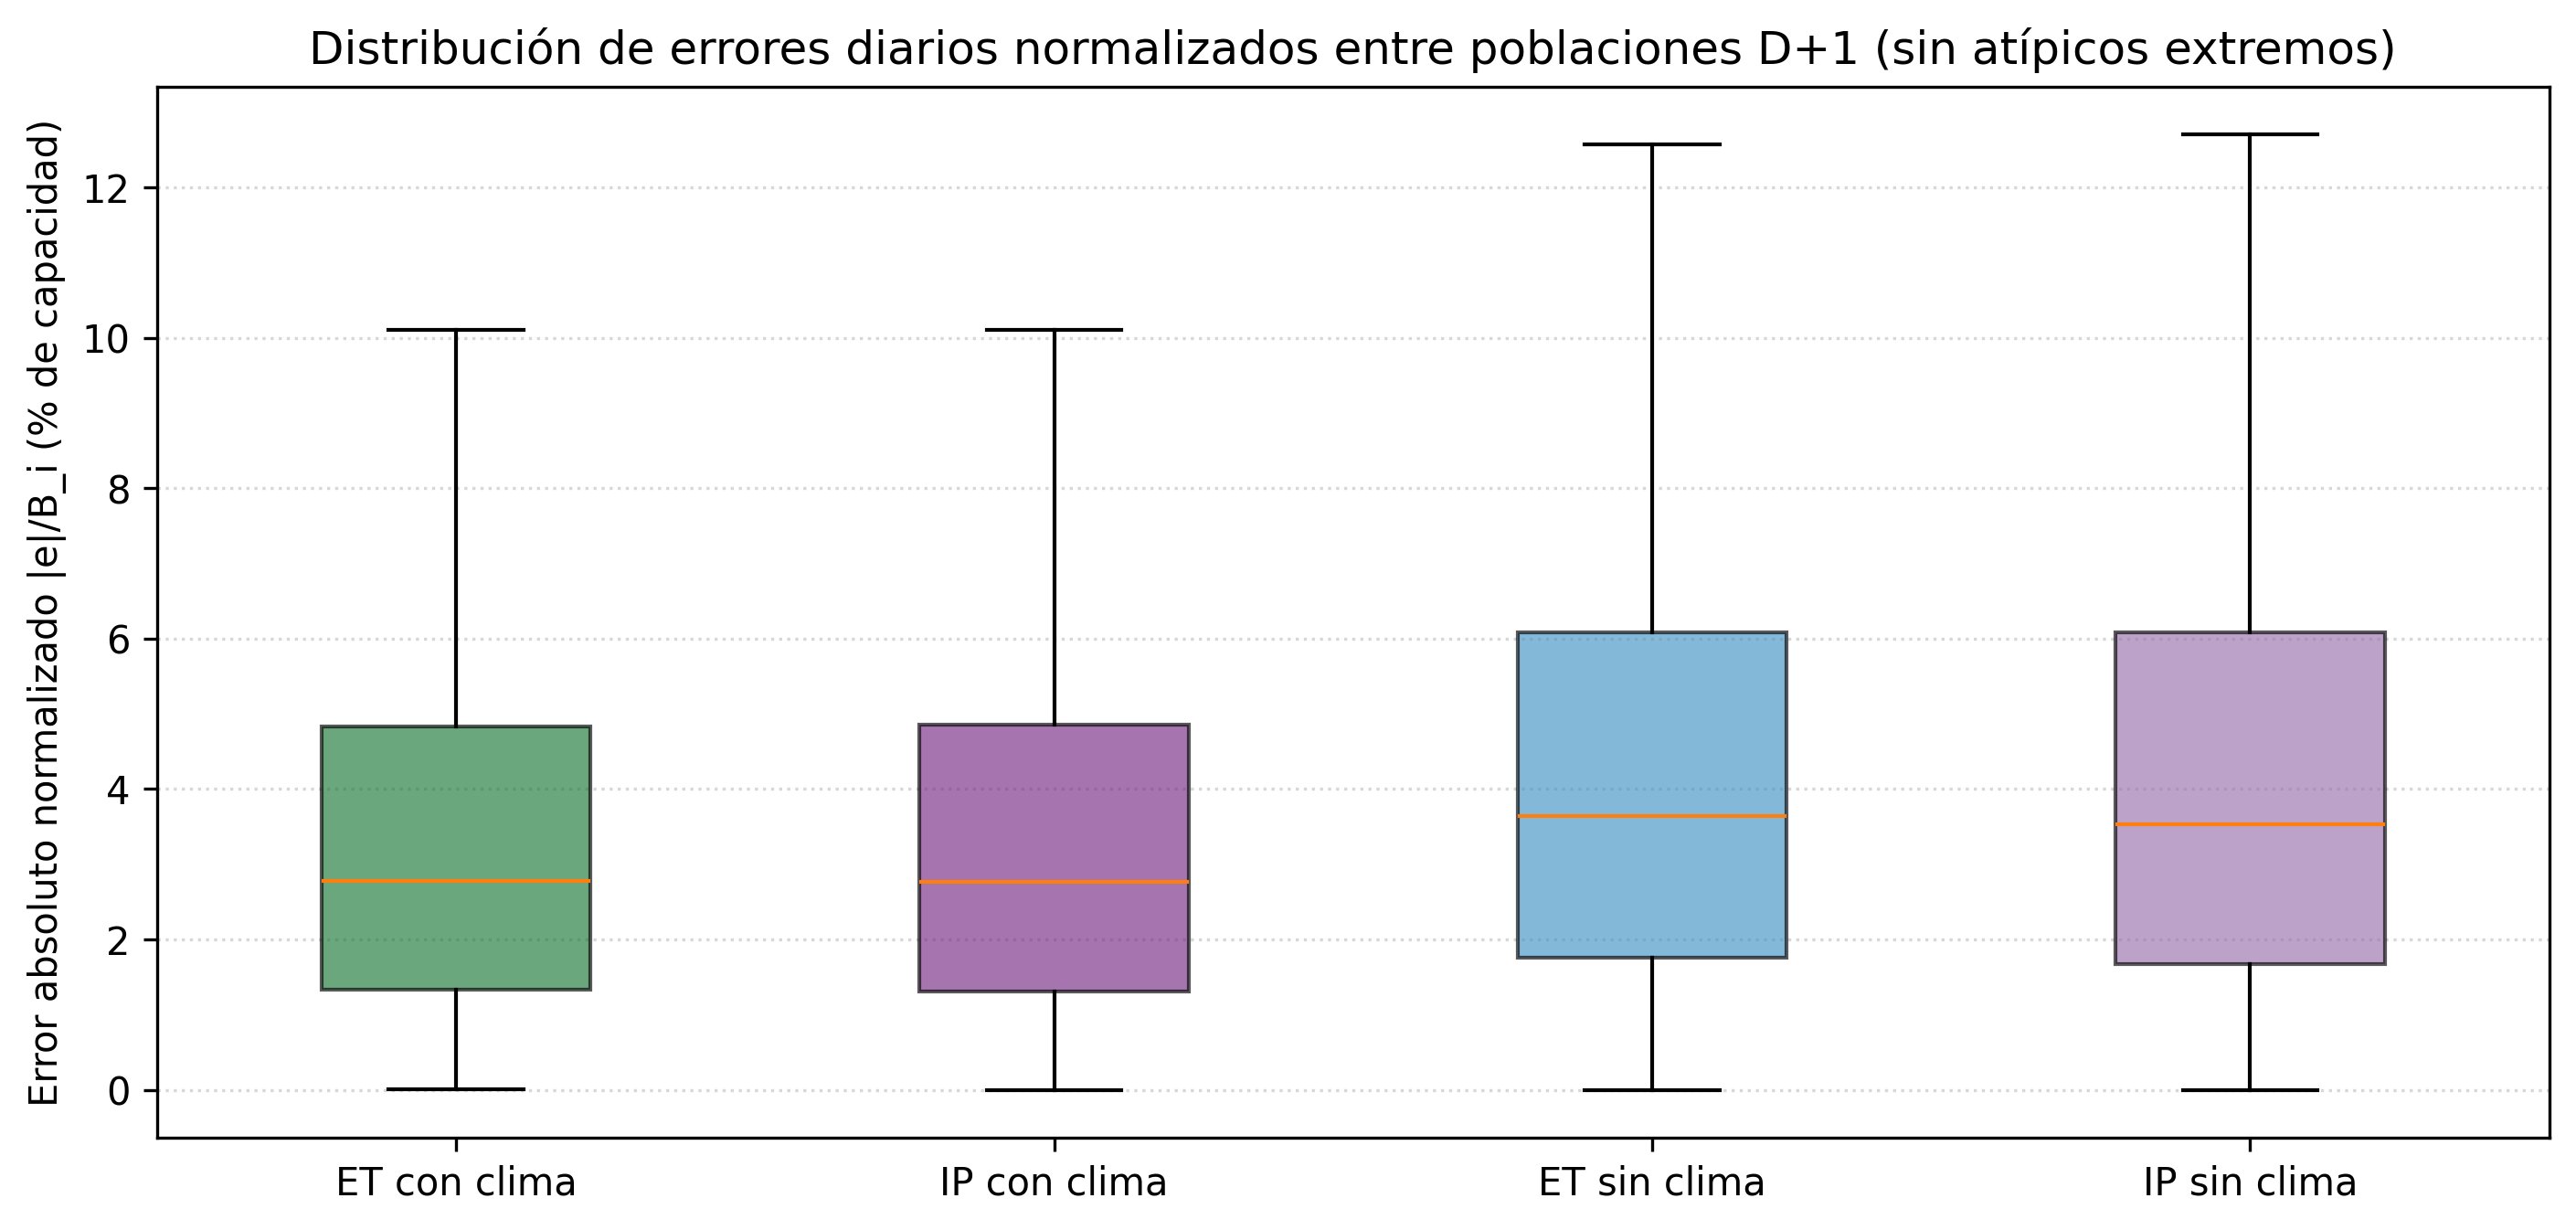

El error absoluto en `kWh/día` crece linealmente con la capacidad instalada, mientras el error normalizado `MAE_CF` se mantiene entre `2.46%` y `5.49%` (`SM-CFHR-Fixed` supera a `Lasso` en `17/17` plantas en `D1_ET_5var`). Entre bloques temporales externos, `MAE_CF` aumenta de `D1` a `D3`, reflejando deriva temporal en la flota analizada. Por estrategia, `Recursivo + GEFSv12` reduce el crecimiento del error multihorizonte frente a `Recursivo sin clima` y `Directo sin clima / H`, y reduce la dispersión de los errores diarios normalizados en `P14`.

In [11]:
if ped_figs:
    intra_p = pd.read_csv(OOF_DIR / "metricas" / "intra_por_planta_capacidad.csv")
    display(intra_p.sort_values("MAE_CF_ASHR").head(8))
    display(Image(filename=str(ped_figs["P11"][0])))
    display(Image(filename=str(ped_figs["P12"][0])))
    display(Image(filename=str(ped_figs["P14"][0])))
    cf_min, cf_max = intra_p["MAE_CF_ASHR"].min() * 100.0, intra_p["MAE_CF_ASHR"].max() * 100.0
    n_p_win = int((intra_p["MAE_CF_ASHR"] < intra_p["MAE_CF_MejorBib"]).sum())
    display(Markdown(
        f"El error absoluto en `kWh/día` crece linealmente con la capacidad instalada, mientras el error normalizado `MAE_CF` se mantiene entre `{cf_min:.2f}%` y `{cf_max:.2f}%` (`SM-CFHR-Fixed` supera a `Lasso` en `{n_p_win}/17` plantas en `D1_ET_5var`). "
        f"Entre bloques temporales externos, `MAE_CF` aumenta de `D1` a `D3`, reflejando deriva temporal en la flota analizada. "
        f"Por estrategia, `Recursivo + GEFSv12` reduce el crecimiento del error multihorizonte frente a `Recursivo sin clima` y `Directo sin clima / H`, y reduce la dispersión de los errores diarios normalizados en `P14`."
    ))

# Capítulo 6. Transferencia entre plantas y grupos geográficos

Esta sección evalúa la generalización a plantas no vistas (`ET`) frente al pronóstico sobre la historia futura de cada planta (`IP`) entre los `7` grupos geográficos del panel colombiano. No incluye conjuntos de datos externos fuera del dominio solar nacional.

,grupo,MAE_CF_ET,MAE_CF_IP,rango_en_10_libs_ET
0,1,0.038433,0.039304,1
1,2,0.045744,0.044127,2
2,3,0.036175,0.035859,1
3,4,0.032159,0.033631,1
4,5,0.032502,0.030922,3
5,6,0.029379,0.029488,1
6,7,0.054923,0.117360,1


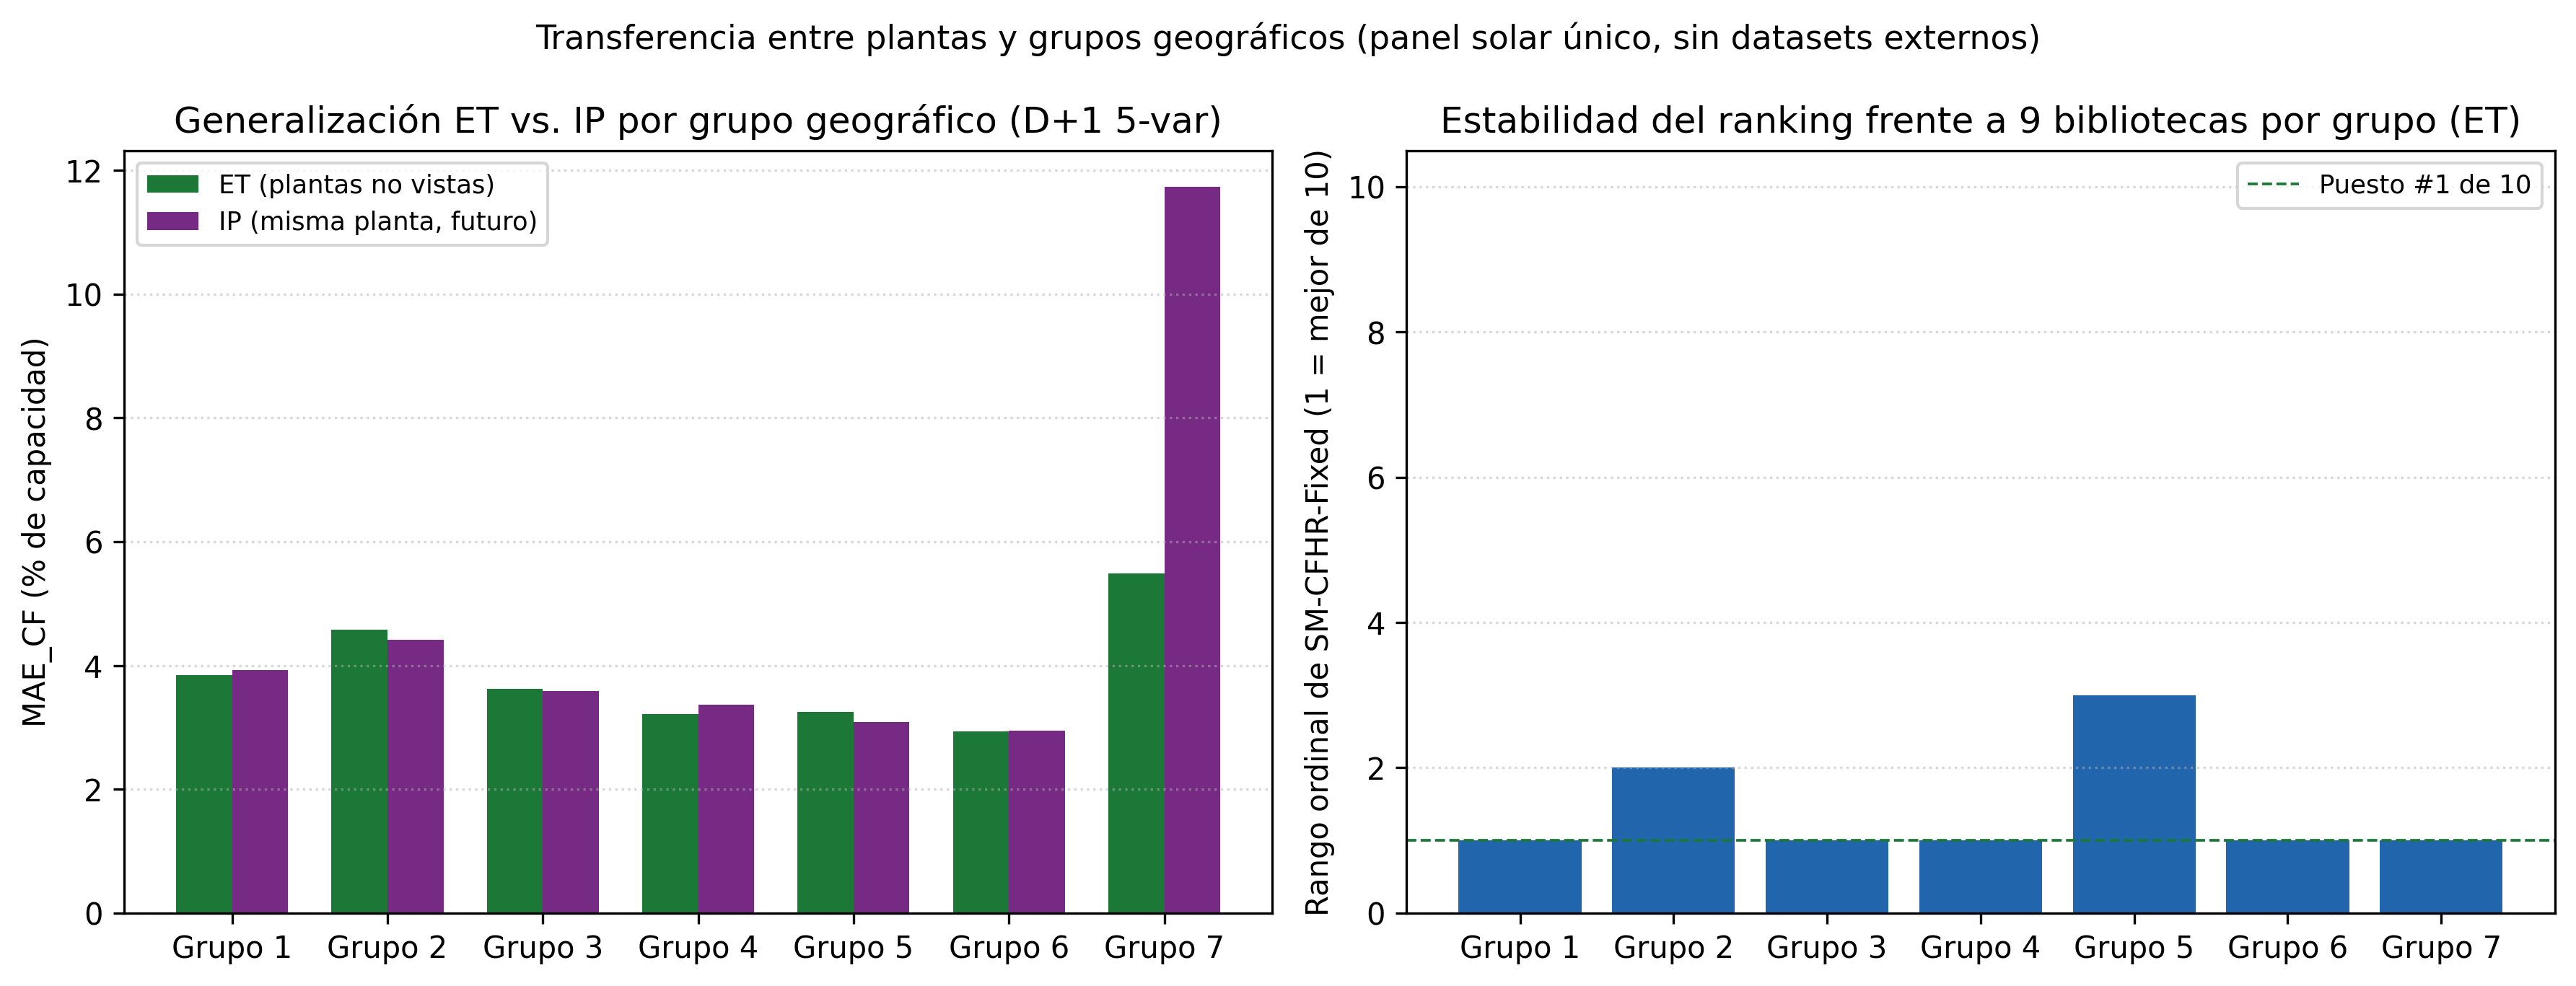

En `D+1` con meteorología, el esquema `ET` iguala o supera a `IP` en `4/7` grupos geográficos en `MAE_CF`, y `SM-CFHR-Fixed` conserva el rango `#1` a `#3` de `10` bibliotecas en todos los grupos. El aporte específico de la normalización y las restricciones monótonas se evalúa en la ablación controlada del Capítulo 7. Esta transferencia entre grupos del mismo panel no sustituye a una validación externa en otras redes o climas.

In [12]:
if ped_figs:
    inter_g = pd.read_csv(OOF_DIR / "metricas" / "inter_grupo_et_vs_ip.csv")
    display(inter_g)
    display(Image(filename=str(ped_figs["P13"][0])))
    rk_max = int(inter_g["rango_en_10_libs_ET"].max())
    n_et_better = int((inter_g["MAE_CF_ET"] <= inter_g["MAE_CF_IP"]).sum())
    display(Markdown(
        f"En `D+1` con meteorología, el esquema `ET` iguala o supera a `IP` en `{n_et_better}/{len(inter_g)}` grupos geográficos en `MAE_CF`, y `SM-CFHR-Fixed` conserva el rango `#1` a `#{rk_max}` de `10` bibliotecas en todos los grupos. "
        f"El aporte específico de la normalización y las restricciones monótonas se evalúa en la ablación controlada del Capítulo 7. Esta transferencia entre grupos del mismo panel no sustituye a una validación externa en otras redes o climas."
    ))

# Capítulo 7. Configuración fija frente a HPO, diagnósticos en D+1 y coste computacional

Se contrasta el rendimiento y coste de `SM-CFHR-Fixed` ($B=0$) frente a `SM-CFHR-HPO` ($B=25$), junto con los estudios diagnósticos ejecutados sobre el panel real `D+1` (ablación, calibración conformal e importancia de variables).

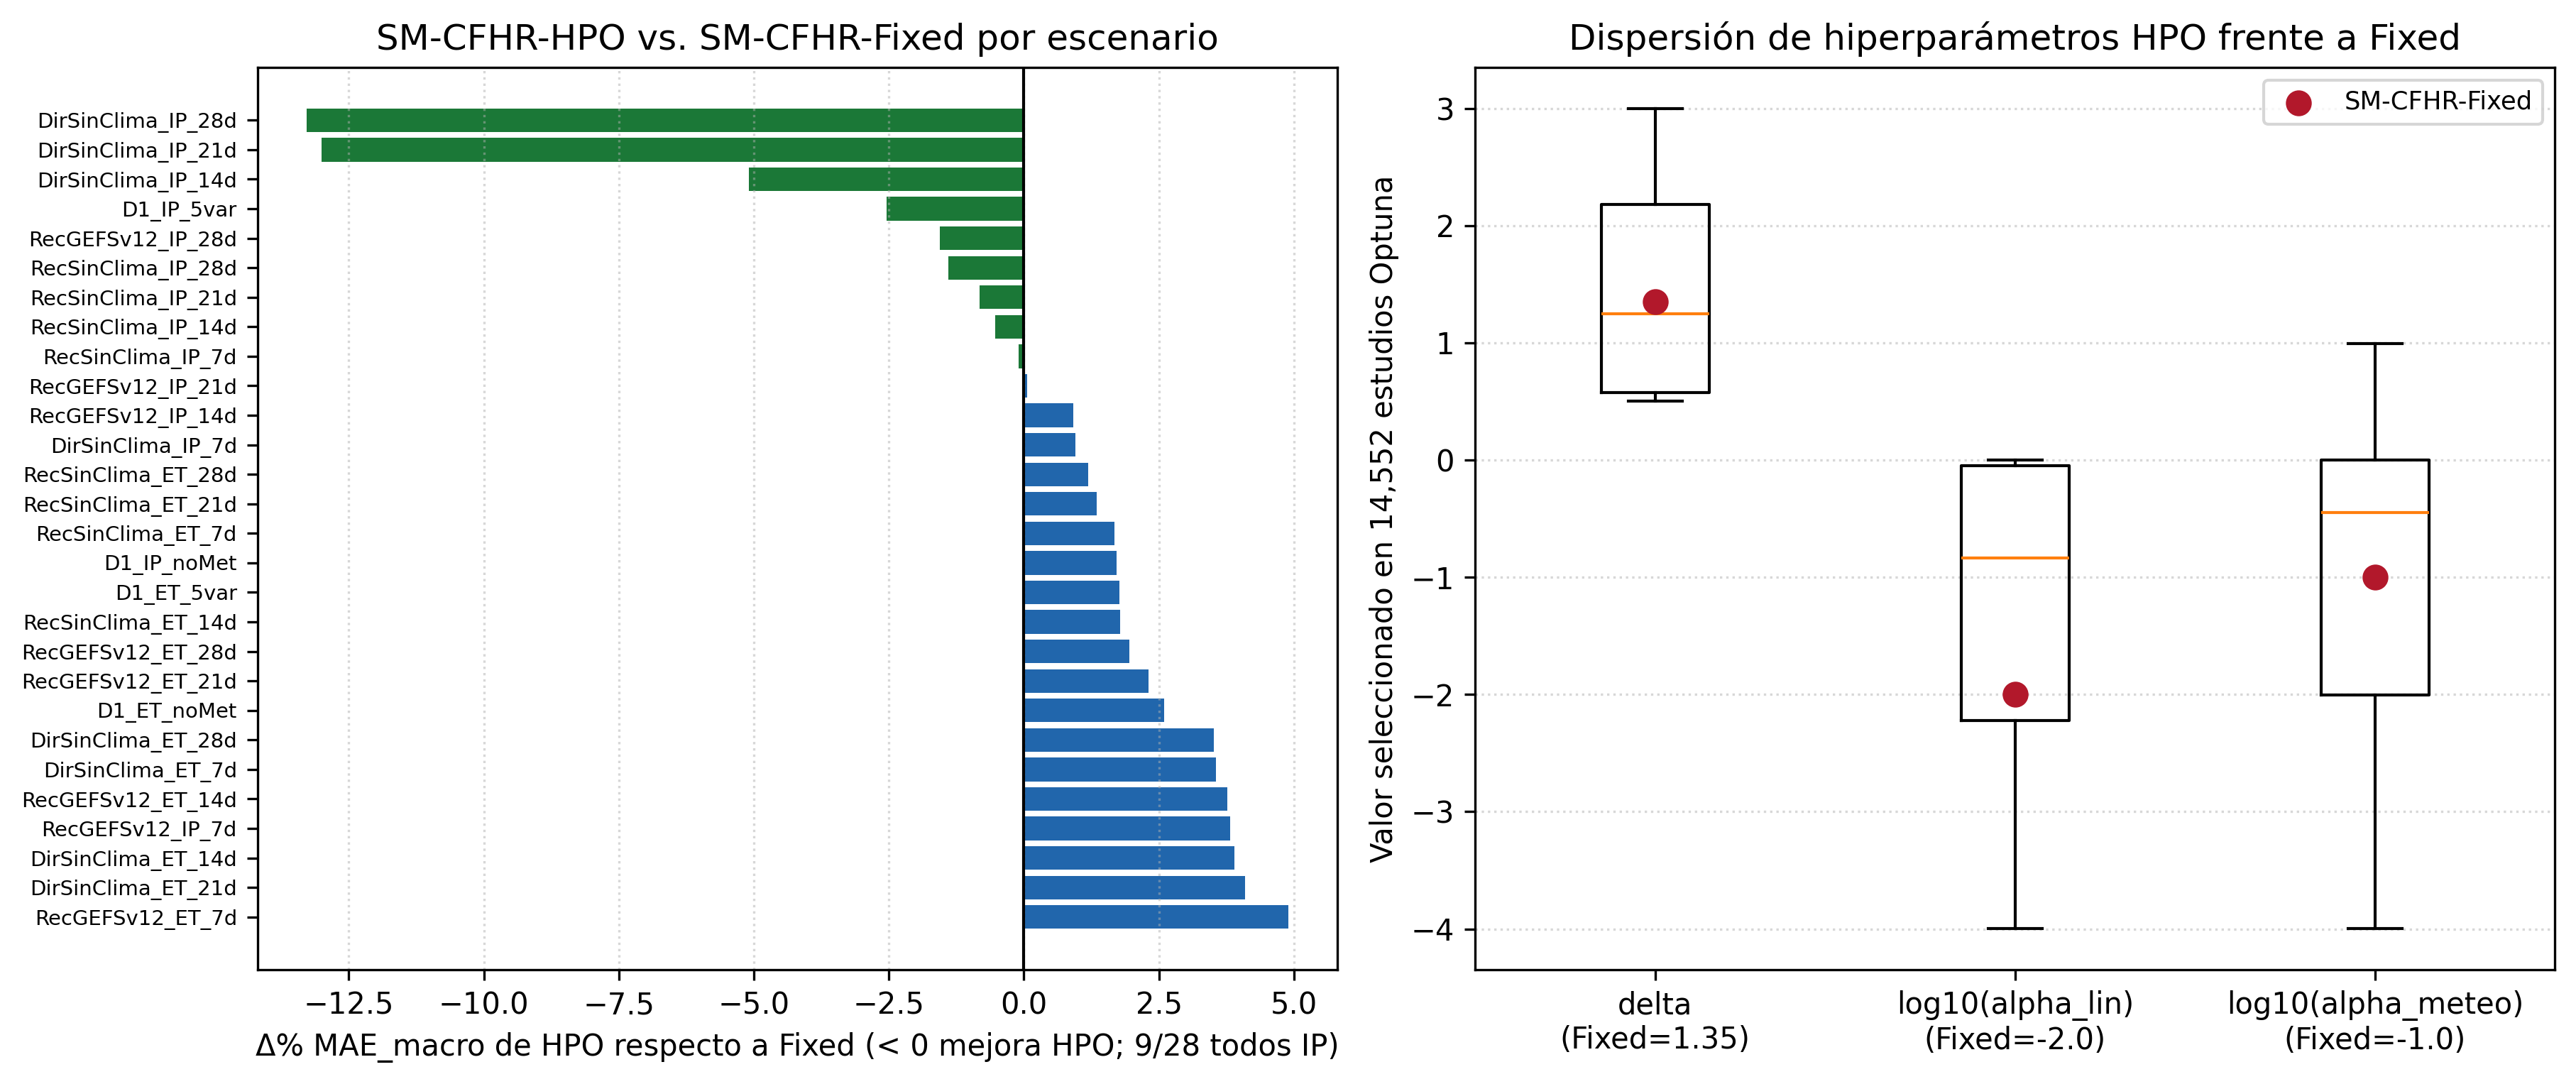

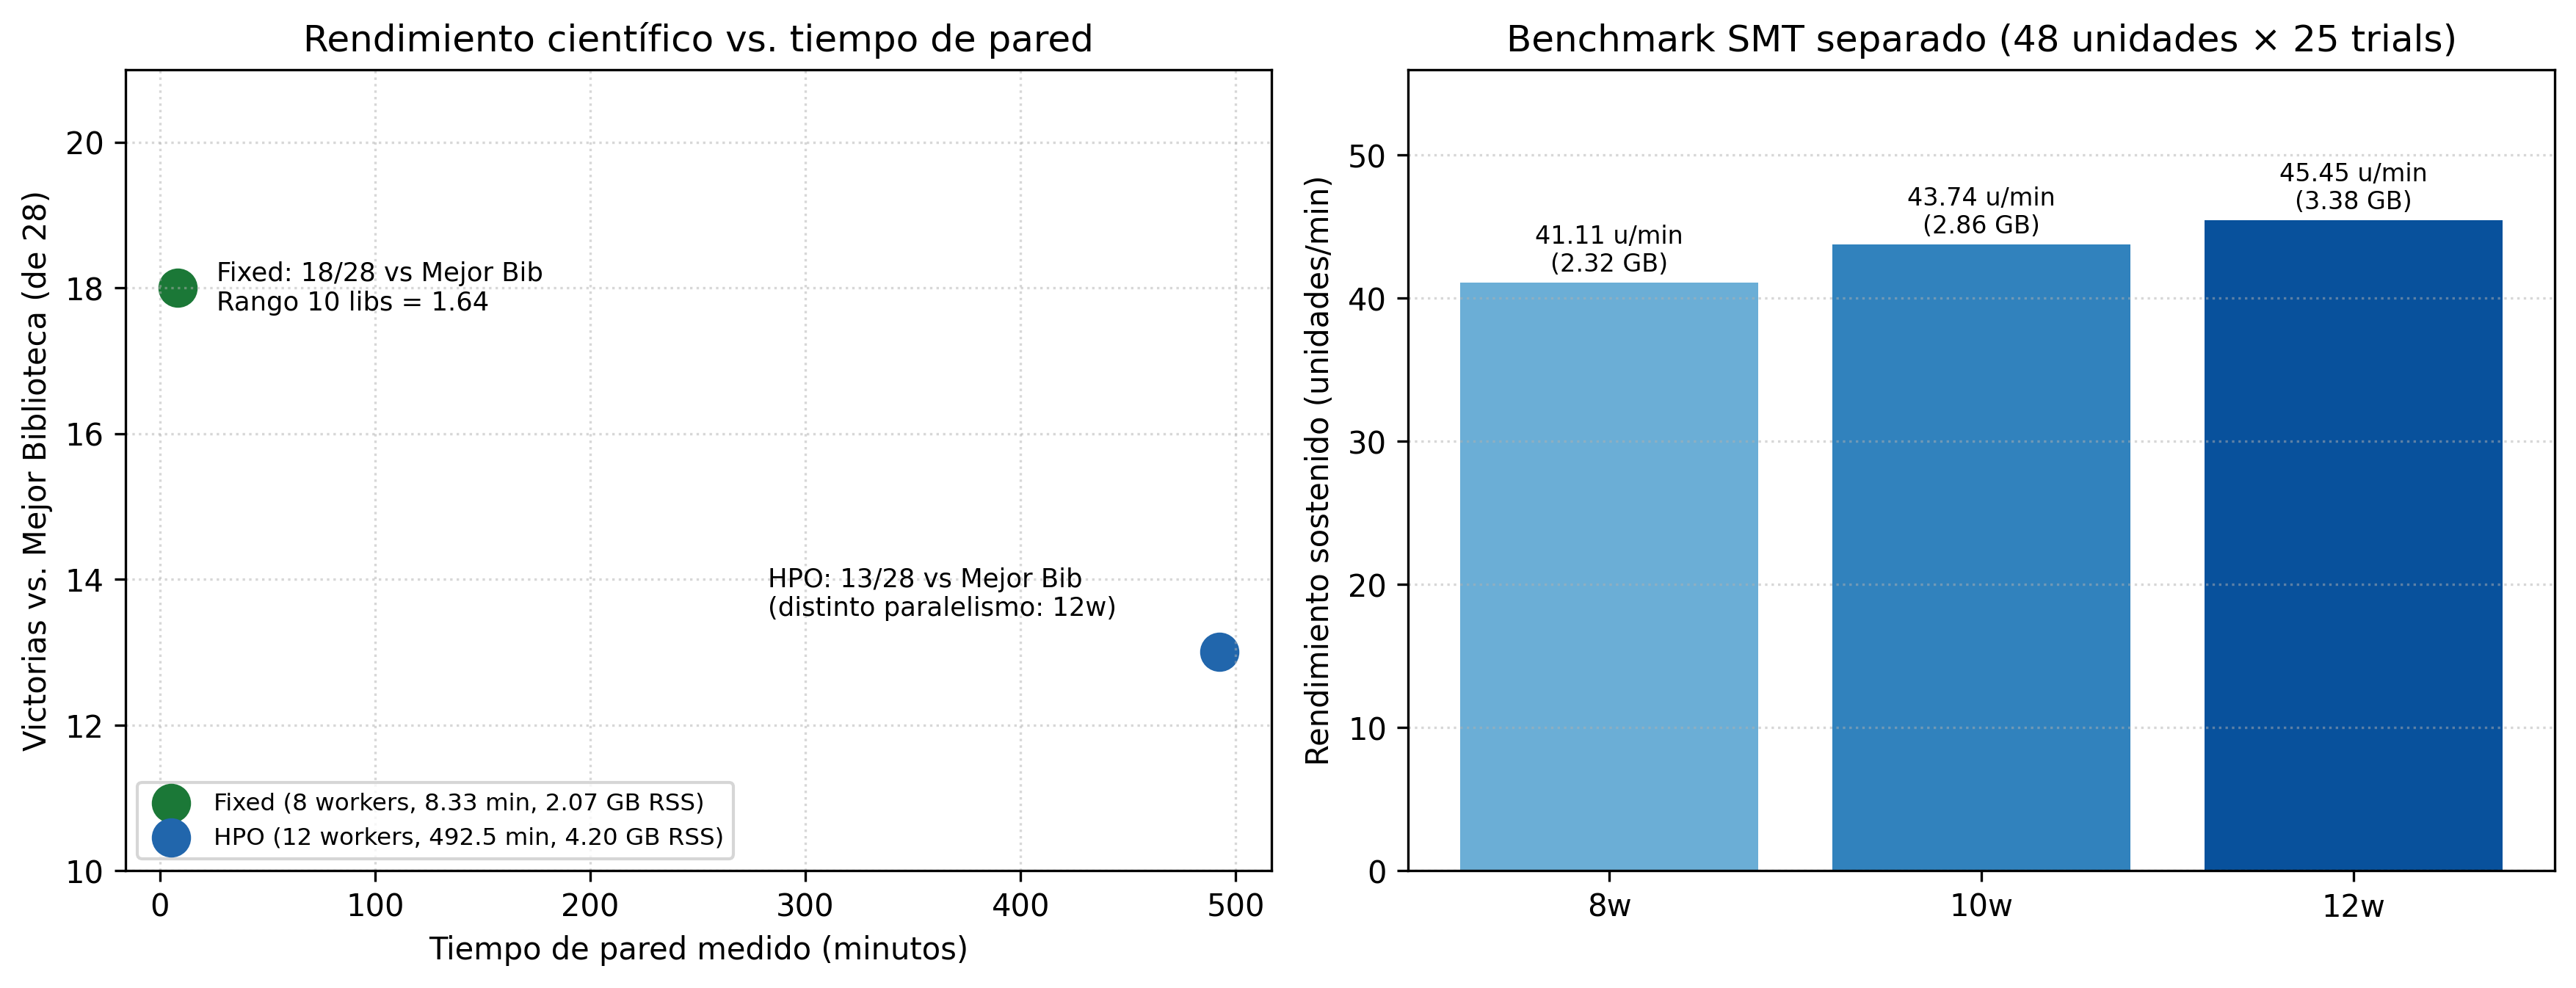

,ablation_variant,mae_cf,mae_kwh
0,SM-CFHR_completo,0.034878,60631.214754
1,sin_huber_L2,0.034961,60784.002789
2,sin_l2_estructurada,0.034870,60606.282762
3,sin_monotonia,0.034878,60631.214754
4,escala_std_vs_mad,0.034878,60631.214754
5,energia_bruta_vs_cf,0.230646,270035.482533


,nominal_coverage,alpha,conformal_halfwidth,mean_width,n_cal,empirical_coverage
0,0.9,0.1,0.066183,0.132366,1720,0.832412
1,0.8,0.2,0.047970,0.095941,1720,0.692478


,feature,std_coef,mean_abs_contrib
0,cf30,0.459142,0.025500
1,anom_rad,0.173094,0.010687
2,anom_nube,-0.172986,0.010673
3,month_cos,-0.110761,0.007015
4,doy_sin,-0.090567,0.005283
5,doy_cos,0.078546,0.005277


`SM-CFHR-HPO` mejora a `SM-CFHR-Fixed` únicamente en `9/28` escenarios (`0/14` en `ET`), todos intraplanta. `Fixed` obtiene mejor rango medio entre bibliotecas (`1.64` frente a `2.25`) empleando `499.75 s` (`8` workers, `2.07 GB` RSS) frente a `29,550.29 s` (`12` workers, `4.20 GB` RSS), aunque las mediciones de tiempo corresponden a niveles distintos de paralelismo.

En los diagnósticos sobre `D+1`: eliminar la normalización `CF` eleva el error de `0.0349` a `0.2306` (`4.45×`); la pérdida Huber mantiene menor error bajo `10%` de valores atípicos (`0.03491` frente a `0.03749` con `L2`); los pesos de las variables monótonas positivas se mantienen positivos (`cf30=+0.459`, `rad_pron=+0.086`); y los intervalos conformes presentan subcobertura empírica (`83.2%` para nominal `90%` y `69.2%` para `80%`). Estos diagnósticos se evaluaron en `D+1` y no se extendieron a los horizontes largos.

In [13]:
if bundle is not None:
    fh_df = pd.read_csv(OOF_DIR / "metricas" / "comparacion_fixed_vs_hpo.csv")
    display(Image(filename=str(ped_figs["P08"][0])))
    display(Image(filename=str(ped_figs["P09"][0])))
    abl_df = pd.read_csv(OOF_DIR / "ablaciones" / "tabla_ablaciones.csv")
    conf_df = pd.read_csv(OOF_DIR / "incertidumbre" / "tabla_conformal_resumen.csv")
    interp_df = pd.read_csv(OOF_DIR / "interpretabilidad" / "tabla_importancia_global.csv")
    display(abl_df)
    display(conf_df)
    display(interp_df.head(6))
    n_hpo_w = int((fh_df["diff_macro_HPO_minus_Fixed"] < 0).sum())
    n_hpo_et = int((fh_df.loc[fh_df["task"] == "espaciotemporal", "diff_macro_HPO_minus_Fixed"] < 0).sum())
    display(Markdown(
        f"`SM-CFHR-HPO` mejora a `SM-CFHR-Fixed` únicamente en `{n_hpo_w}/28` escenarios (`{n_hpo_et}/14` en `ET`), todos intraplanta. `Fixed` obtiene mejor rango medio entre bibliotecas (`1.64` frente a `2.25`) empleando `499.75 s` (`8` workers, `2.07 GB` RSS) frente a `29,550.29 s` (`12` workers, `4.20 GB` RSS), aunque las mediciones de tiempo corresponden a niveles distintos de paralelismo.\n\n"
        f"En los diagnósticos sobre `D+1`: eliminar la normalización `CF` eleva el error de `0.0349` a `0.2306` (`4.45×`); la pérdida Huber mantiene menor error bajo `10%` de valores atípicos (`0.03491` frente a `0.03749` con `L2`); los pesos de las variables monótonas positivas se mantienen positivos (`cf30=+0.459`, `rad_pron=+0.086`); y los intervalos conformes presentan subcobertura empírica (`83.2%` para nominal `90%` y `69.2%` para `80%`). Estos diagnósticos se evaluaron en `D+1` y no se extendieron a los horizontes largos."
    ))

# Capítulo 8. Síntesis de hallazgos y limitaciones

1. **Desempeño frente a bibliotecas:** `SM-CFHR-Fixed` ocupa el rango medio `1.64 / 10` entre las nueve bibliotecas, supera a cada biblioteca individual en `23`–`28/28` escenarios, vence en `18/28` escenarios al mejor competidor *ex post* y permanece en el MCS exclusivo de bibliotecas en `28/28` casos.
2. **Alcance de la superioridad estadística:** Bajo el protocolo congelado (`v1.0.3`, estimando `MAE_promedio_por_origen` con filtro $T_{\mathrm{eff}} \ge 2H$, `Mejor_Bib` retrospectivo, Holm por familia), la superioridad tras ajuste Holm-Bonferroni y con tamaño del efecto grande queda acreditada en `2/15` escenarios (`D1_ET_5var` con `-22.2%`, $d_z=-0.898$; `RecGEFSv12_ET_7d` con `-13.4%`, $d_z=-0.653$). En la revisión independiente `v2.0.0` (`auditoria_inferencia_estadistica.ipynb` y `resultados/inferencia_revision_independiente_v2/`), al alinear DM-HLN-HAC y MCS/SPA con el estimando `MAE_macro` y usar `h_overlap=1` real, la superioridad significativa tras Holm se extiende a los `5` escenarios `ET + Clima` (`D1`, `7d`–`28d`), pero **no** al régimen intraplanta ni al conjunto completo de `28` escenarios.
3. **Comportamiento por planta, régimen y presupuesto:** La normalización por capacidad estabiliza el error relativo entre centrales de `9.8` y `388 MW` y a través de `7` grupos geográficos. Las principales derrotas se concentran en `DirectoSinClima_IP` (`+13.3%` medio frente a `k-NN`). Por último, `SM-CFHR-Fixed` ($B=0$) supera a `SM-CFHR-HPO` ($B=25$) en `19/28` escenarios (`14/14` en `ET`) con un coste computacional `~59×` menor.
4. **Limitaciones abiertas:** Persisten la subcobertura conformal en `D+1` (`83.2%` para `90%`), la dependencia entre los `28` escenarios del mismo panel solar, el hecho de que las `22` referencias comparadas operaron en energía bruta (`kWh`) y la ausencia de validación en conjuntos externos (sin datasets externos).

In [14]:
if bundle is not None:
    resumen_desc = build_descriptive_summary(bundle)
    export_paper_tables(bundle, TAB_DIR)
    design_df = analyze_effective_design(bundle)
    full_manifest = export_full_scientific_artifacts(
        bundle,
        OOF_DIR,
        extra_artifacts={
            "conclusiones/veredicto_r3": r3_verdict_df,
            "inferencia/diseno_efectivo": design_df,
            "conclusiones/resumen_descriptivo": resumen_desc,
        },
    )
    print("Artefactos exportados:", full_manifest["n_archivos_exportados"])

Artefactos exportados: 25
